# Repetition Code and Hamming (7, 4) Code: Hard Decision Decoding

# Simulation Setup: BPSK over an AWGN Channel

- We consider transmission over an Additive White Gaussian Noise (AWGN) channel.

- Received sequence: $y = x + w$, where $x = 2c - 1$ (BPSK modulated codeword, where $c$ is the codeword of an input message sequence $m$)

- The noise vector $w$ follows a complex Gaussian distribution with mean $\mu = 0$ and variance $\sigma^2 = N_0$

- $w \sim \mathcal{CN}(\mu = 0, \sigma^2_c = N_0)$, and the noise can be written as $w = w_r + j w_i$, where $w_r$ and $w_i$ are the real and imaginary Gaussian noise samples, each distributed as $w_r, w_i \sim \mathcal{N}(0, N_0/2)$

- Since the BPSK modulated signal $x$ is purely real (no imaginary component), only the real part of the noise affects the received signal.

- Therefore, the received sequence simplifies to: $y = x + w_r$, where $w_r \sim \mathcal{N}(\mu = 0, \sigma^2_r = N_0/2)$

# Part 1: Repetition (3, 1) Code

- With a (n = 3, k = 1) repetition code, we have 1 information bit and we add 2 parity bits to form the 3 coded bits. Each message bit is simply repeated three times.

- Assuming that the message sequence (MESSAGE BIT) is $m = [m_0]$, then the coded output sequence (CODEWORD) is : $c = [m_0, p_0, p_1]$

- Parity bits: $p_0 = m_0$, $\; \; p_1 = m_0$

- There are $2^k = 2$ possible message sequences: $[0]$ and $[1]$, and $2^k = 2$ corresponding codewords: $[0, 0, 0]$ and $[1, 1, 1]$.

- Code rate $= k/n = 1/3$

## Generator Matrix and Parity Check Matrix

- Codeword $c = (m G)$ mod 2, with $G = [I_k \mid P] = \begin{pmatrix} 1 & 1 & 1 \end{pmatrix}$ of size $[k \times n] = [1 \times 3]$

- $H = [P^{\rm T} \mid I_{n-k}] = \begin{pmatrix}
1 & 1 & 0 \\
1 & 0 & 1
\end{pmatrix}$ of size $[(n-k) \times n] = [2 \times 3]$

- $c$ is a valid codeword if and only if $(cH^{\rm T})$ mod 2 $= 0$

### Minimum distance

- The two codewords $[0, 0, 0]$ and $[1, 1, 1]$ differ in all three positions, so $d_{min} = 3$

- Number of errors which can be detected is $d_{min} - 1 = 2$

- Number of errors which can be corrected is $t =$ round_down $(\frac{d_{\min} -1}{2}) = 1$

## Hard Decision Decoding (Syndrome Decoding and Majority Vote)

- Example message sequence: $m = [1]$, corresponding codeword: $c = (mG)$ mod 2 $= [1 \; 1 \; 1]$

- Modulated sequence (BPSK): $x = 2c - 1 = [1 \; 1 \; 1]$

- Let the received sequence be $y = [0.94, \; -0.37, \; 1.21]$

- Demodulated sequence: map to bit 1 if $y_j > 0$ else map to bit 0 for all $j \in \{1, 2, 3\}$, which gives $b = [1 \; 0 \; 1]$

- Syndrome vector: $s = (b H^{\rm T})$ mod 2 $= [1 \; 0]$, which is of size $[1 \times (n-k)]$

- $s$ resembles the $2^{\rm nd}$ column of $H$. Hence, the error is in the $2^{\rm nd}$ bit position of the demodulated sequence. Flip that bit to correct the codeword: $\hat{c} = [1 \; 1 \; 1]$ and the message is $\hat{m} = [1]$

- If $s = [0 \; 0]$, there are no errors in the demodulated sequence, hence $\hat{c} = b$

- For the repetition code, this syndrome decoder is the same as a **majority vote** over the three demodulated bits: here two bits are 1 and one bit is 0, so the decoded bit is 1.

- If there are 2 or more bit errors, the majority is wrong and the decoded bit is incorrect. The (3, 1) repetition code can correct only a 1-bit error.

#### **Step 1:** Generate a random binary message sequence $m$ of length $k = 1$

#### **Step 2:** Generate the codeword for the message $m$, $c = (mG)$ mod 2, where $G = [1 \; 1 \; 1]$ is the generator matrix

#### **Step 3:** Modulate the codeword (BPSK): $x = 2c - 1$

#### **Step 4:** Select a $N_0$ value (say $N_0 = 1$)

#### **Step 5:** Generate a real Gaussian noise sequence $w_r$ of length $n = 3$ with mean $\mu = 0$ and variance $\sigma^2_r = N_0/2$ (use np.random.normal with standard deviation $\sqrt{N_0/2}$)

#### **Step 6:** Obtain the received sequence $y = x + w_r$

#### **Step 7:** Using $y$, perform hard decision decoding (syndrome decoding or majority vote) and obtain the decoded message $\hat{m}$

#### **Step 8:** Count Error $Err = 1$ if $\hat{m} \neq m$ else $Err = 0$

In [1]:
# Write your code here
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
G_rep = np.array([[1, 1, 1]], dtype=int)
H_rep = np.array([[1, 1, 0], [0, 1, 1]], dtype=int)
G_ham = np.array([
    [1, 0, 0, 0, 1, 0, 1],
    [0, 1, 0, 0, 1, 1, 1],
    [0, 0, 1, 0, 1, 1, 0],
    [0, 0, 0, 1, 0, 1, 1]
], dtype=int)
H_ham = np.array([
    [1, 1, 1, 0, 1, 0, 0],
    [0, 1, 1, 1, 0, 1, 0],
    [1, 1, 0, 1, 0, 0, 1]
], dtype=int)

def hard_decision(y):
    # Lab convention: bit 0 -> -1 and bit 1 -> +1
    return (np.asarray(y) > 0).astype(int)

def encode_repetition(m):
    return np.repeat(np.asarray(m, dtype=int), 3)

def decode_repetition(y):
    b = hard_decision(y).reshape(-1, 3)
    return (np.sum(b, axis=1) >= 2).astype(int)

def encode_hamming(m):
    m = np.asarray(m, dtype=int).reshape(-1, 4)
    return (m @ G_ham) % 2

def decode_hamming(y):
    b = hard_decision(y).reshape(-1, 7)
    decoded = b.copy()
    # Syndrome columns identify the bit position to flip.
    syndromes = (b @ H_ham.T) % 2
    # Convert each 3-bit syndrome to its integer value (1..7); columns of H
    # are the binary labels of the seven correctable bit positions.
    syndrome_values = syndromes[:, 0]*4 + syndromes[:, 1]*2 + syndromes[:, 2]
    column_values = H_ham[0, :]*4 + H_ham[1, :]*2 + H_ham[2, :]
    for bit_pos, value in enumerate(column_values):
        decoded[syndrome_values == value, bit_pos] ^= 1
    return decoded[:, :4]

def bpsk(bits):
    return 2*np.asarray(bits, dtype=float) - 1

def awgn(x, No, rng=rng):
    return x + rng.normal(0, np.sqrt(No/2), size=np.shape(x))


#### **Step 9: Bit Error Rate (BER)**

- Repeat Step 1 to Step 8 for N_blocks $= 10^6$ times and count the total number of errors.

- Since $k = 1$, every block carries one message bit, so **Block Error Rate (BLER) = Bit Error Rate (BER)** = Total number of errors / N_blocks

- Report (Print): At given $N_0 = 1$, BER $=$ ________________

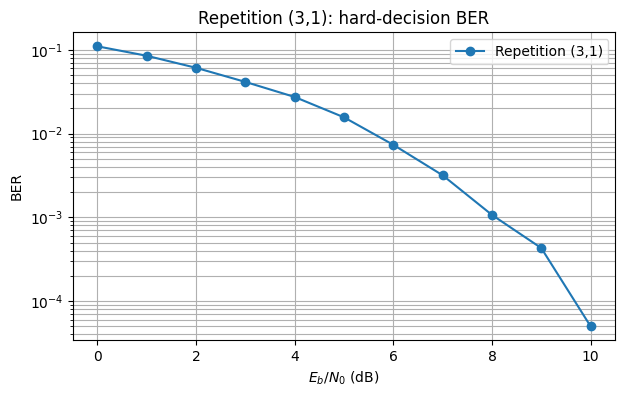

In [2]:
# Plot repetition-code BER versus Eb/No. The codeword energy is n=3,
# so Eb = 3/1 = 3 under unit-amplitude BPSK; No = Eb / 10^(EbNo_dB/10).
EbNo_dB_arr = np.arange(0, 11, 1)
rep_ber = []
N_sweep = 100_000
for ebno_db in EbNo_dB_arr:
    No_i = 3 / (10**(ebno_db/10))
    msg = rng.integers(0, 2, N_sweep)
    rx = awgn(bpsk(encode_repetition(msg)), No_i)
    dec = decode_repetition(rx)
    rep_ber.append(np.mean(msg != dec))
plt.figure(figsize=(7,4))
plt.semilogy(EbNo_dB_arr, np.maximum(rep_ber, 1/(N_sweep)), 'o-', label='Repetition (3,1)')
plt.xlabel(r'$E_b/N_0$ (dB)'); plt.ylabel('BER'); plt.title('Repetition (3,1): hard-decision BER')
plt.grid(True, which='both'); plt.legend(); plt.show()


#### **Step 10: Plot EbNo[dB] vs BER**

- Eb = Energy per bit = (Total energy of a codeword) / (Number of encoded message bits)

- Energy of each modulated codeword $= \|x\|^2_2 = 3 = n$, and the number of encoded message bits in each codeword is $k = 1$. Hence, Eb $= n/k = 3$

- EbNo $= 3/N_0$ and EbNo_dB $= 10 \log_{10}$ (EbNo)

- Given EbNo_dB_arr = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], find the $N_0$ for each value, simulate, and plot EbNo_dB vs BER (y-axis in log scale)

- Your plot should look like below.

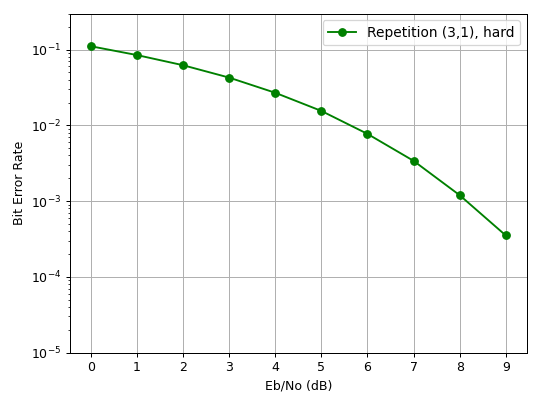

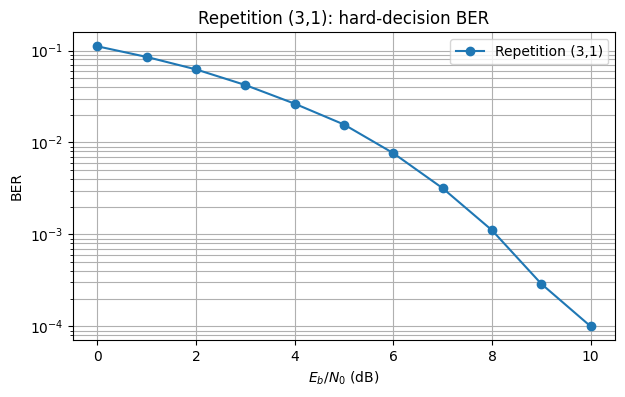

In [3]:
# Plot repetition-code BER versus Eb/No. The codeword energy is n=3,
# so Eb = 3/1 = 3 under unit-amplitude BPSK; No = Eb / 10^(EbNo_dB/10).
EbNo_dB_arr = np.arange(0, 11, 1)
rep_ber = []
N_sweep = 100_000
for ebno_db in EbNo_dB_arr:
    No_i = 3 / (10**(ebno_db/10))
    msg = rng.integers(0, 2, N_sweep)
    rx = awgn(bpsk(encode_repetition(msg)), No_i)
    dec = decode_repetition(rx)
    rep_ber.append(np.mean(msg != dec))
plt.figure(figsize=(7,4))
plt.semilogy(EbNo_dB_arr, np.maximum(rep_ber, 1/(N_sweep)), 'o-', label='Repetition (3,1)')
plt.xlabel(r'$E_b/N_0$ (dB)'); plt.ylabel('BER'); plt.title('Repetition (3,1): hard-decision BER')
plt.grid(True, which='both'); plt.legend(); plt.show()


# Part 2: Hamming (7, 4) Code

- With a (n = 7, k = 4) Hamming code, we have 4 information bits and we need to add 3 parity bits to form the 7 coded bits.

- Assuming that the message sequence (MESSAGE BITs) is $m = [m_0, m_1, m_2, m_3]$, then the coded output sequence (CODEWORD) is : $c = [m_0, m_1, m_2, m_3, p_0, p_1, p_2]$

- Parity bits: $p_0 = (m_0 + m_1+ m_2)$ mod 2, $\; \; p_1 = (m_1 + m_2 + m_3)$ mod 2, $\; \; p_2 = (m_0 + m_1 + m_3)$ mod 2

- There are $2^k = 16$ possible message sequences: $[0, 0, 0, 0]$ to $[1, 1, 1, 1]$ and $2^k = 16$ corresponding codewords.

# Encoding

## Generator Matrix

- We can obtain codeword for given input message sequence $m$ using generator matrix $G$

- Codeword $c = (m G)$ mod 2

- $G = \begin{pmatrix}
1 & 0 & 0 & 0 & 1 & 0 & 1 \\
0 & 1 & 0 & 0 & 1 & 1 & 1 \\
0 & 0 & 1 & 0 & 1 & 1 & 0 \\
0 & 0 & 0 & 1 & 0 & 1 & 1
\end{pmatrix}$

- $G = [I_k \mid P]$ ---------------of size $[k \times n]$
- $I_k$ is $[k \times k]$ Identity matrix
- $P$ is $[k \times (n-k)]$ Parity Matrix

### Codebook
- Codebook matrix $C$ of size $[2^k \times n]$ containing all 16 possible codewords.

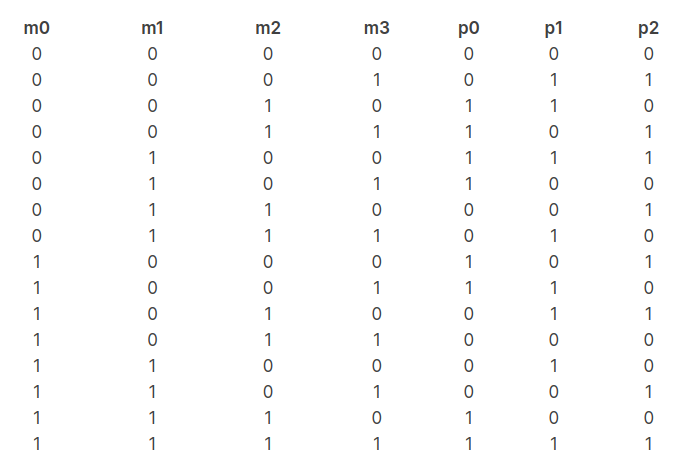

### Minimum distance

- Hamming distance computes the number of differing positions when comparing two code words. For the coded output sequence listed in the table above, we can see that the minimum separation between a pair of code words  is 3, i.e., $d_{min} = 3$

- Number of errors which can be detected is  $d_{min} - 1$ = 2

- Number of errors which can correct (error correction capability of code with  distance  $d_{min}$) is $t =$ round_down $(\frac{d_{\min} -1}{2}) = 1$

## Parity Check Matrix

- $H = [P^{\rm T}| I_{n-k}]$ -------------of size $[(n-k) \times n]$

- $H = \begin{pmatrix}
1 & 1 & 1 & 0 & 1 & 0 & 0 \\
0 & 1 & 1 & 1 & 0 & 1 & 0 \\
1 & 1 & 0 & 1 & 0 & 0 & 1 \\
\end{pmatrix}$

- For any codeword $c \in C$ holds $(cH^{\rm T})$ mod 2 $= 0$
- $c$ is a valid codeword if any only if $(cH^{\rm T})$ mod 2 $= 0$

## Received Codeword

- Example message sequence: $m = [1 \; 1 \; 0 \; 1]$

- Corresponding codeword:  $c = (mG)$ mod 2 $= [1 \; 1 \; 0 \;1 \;0 \;0 \;1]$

- Modulated sequence (BPSK): $x = 2c - 1 =  [1 \; 1 \; -1 \;1 \; -1 \; -1 \;1]$

- Received sequence:  $y = hx + w$, here $h$ is channel gain vector, $w$ is noise vector

- Let Received sequence is $y = [1.27, \; 0.63, \;0.13, \; 0.45, \; -0.78, -0.52, \; 1.34]$

# Hard Decision Decoding (Syndrome Decoding)

- First demodulate the received sequence: map to bit 1 if $y_j > 0$ else map to bit 0 for all $j \in \{1, 2, ..., n\}$

- Demodulated sequence: $b = [1 \; 1 \;  1 \; 1 \; 0 \; 0\; 1]$

- syndrome vector : $s = (b H^{\rm T})$ mod 2  ------ is of size $[1 \times (n-k)]$

- $s$ resembles to a specific column of $H$

-  $s = [1 \;1 \;0]$ ; It is similar to $3^{\rm rd}$ column in Parity check matrix $H$.

- Hence, error is in $3^{\rm rd}$ bit position of demodulated sequence. Flip that 3rd bit to correct the codeword.

- Corrected codeword: $\hat{c} = [1 \; 1 \; 0 \;1 \;0 \;0 \;1]$ and corresponding message sequence $\hat{m} = [1 \;1\; 0\; 1]$

- Note: If $s = [0 \; 0\; 0]$, then there are no errors in demodulated sequence, hence, $\hat{c} = b$

-  If there are 2 or more bit errors,  $(bH^{\rm T})$ mod 2 still give syndrome vector but final corrected codeword $\hat{c}$ will be incorrect. (7, 4) Hamming code can able to correct only 1-bit error.

#### **Step 1:** Generate a random binary message sequence $m$ of length 4

#### **Step 2:** Generate the codeword for input message sequence $m$, $c = (mG)$ mod2,  $G$ is generator matrix

#### **Step 3:** Modulate the codeword (BPSK): $x  = 2c - 1$

#### **Step 4:** Select a $N_0$ value (say $N_0$ = 1)

#### **Step 5:** Generate real Gaussian noise sequence $w_r$ of length ($n = 7$) from the distribution with mean $\mu = 0$ and variance $\sigma^2_r = N_0/2$ using following code.

- ```python
    def generate_gaussian_noise( mean, variance):
        noise = np.random.normal(mean, np.sqrt(variance), 7)
        return noise
    ```

#### **Step 6:** Obtain received sequence $y = x + w_r$

#### **Step 7:** Using $y$, perform Hamming hard decision decoding (syndrome decoding) and obtain the decoded message sequence $\hat{m}$

#### **Step 8:** Count Error $Err = 1$  if $\hat{m} \neq m$ else $Err = $0$

In [4]:
# Hamming (7,4) example: encode, transmit over AWGN, syndrome-decode.
m_demo = np.array([1, 1, 0, 1])
c_demo = encode_hamming(m_demo)[0]
x_demo = bpsk(c_demo)
y_demo = awgn(x_demo, No=0.8)
b_demo = hard_decision(y_demo)
syndrome_demo = (b_demo @ H_ham.T) % 2
decoded_demo = decode_hamming(y_demo)[0]
print("Message:          ", m_demo)
print("Encoded codeword: ", c_demo)
print("Received samples: ", np.round(y_demo, 2))
print("Hard decisions:   ", b_demo)
print("Syndrome:         ", syndrome_demo)
print("Decoded message:  ", decoded_demo)


Message:           [1 1 0 1]
Encoded codeword:  [1 1 0 1 0 0 1]
Received samples:  [ 0.79  0.62  0.07  0.78 -0.74 -1.16  0.03]
Hard decisions:    [1 1 1 1 0 0 1]
Syndrome:          [1 1 0]
Decoded message:   [1 1 0 1]


#### **Step 9: Block Error Rate (BLER)**
-  Repeat Step 1 to Step 8 for N_blocks  = $10^6$ times and count total number of errors.

-  Compute **Block Error Rate (BLER)**  = (Total number of errors) / (total number message sequences) = Total number of errors / N_blocks

- Report (Print): At given $N_0 = 1$, BLER  =________________

In [5]:
# Monte Carlo BLER for Hamming (7,4) at No = 1.
N_blocks = 200_000
No = 1.0
messages = rng.integers(0, 2, size=(N_blocks, 4))
coded = encode_hamming(messages)
received = awgn(bpsk(coded), No)
decoded_m = decode_hamming(received)
total_errors = int(np.count_nonzero(np.any(messages != decoded_m, axis=1)))
BLER = total_errors / N_blocks
BER_hamming = np.mean(messages != decoded_m)
print(f"Hamming (7,4), No={No:.2f}: block errors={total_errors}/{N_blocks}, BLER={BLER:.6g}, BER={BER_hamming:.6g}")


Hamming (7,4), No=1.00: block errors=19745/200000, BLER=0.098725, BER=0.0436812


#### **Step 10: Plot No vs BLER**

-  Perform Step 1-9 for different $N_0$ values.

- Vary the $N_0$ from range $0.2$ to $2.2$ and obtain results (BLERs)

- Plot $N_0$ vs BLER, plot y-axis in dB scale

- Your plot should look like below.

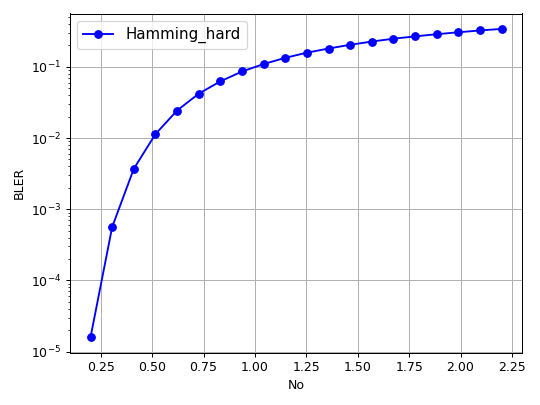

## How to Plot Eb/No[dB] vs BLER ?

- Eb = Energy per bit = (Total Energy of a codeword) / (Number of encoded message bits)

- Energy of each modulated codeword = $\|x\|^2_2$ = 7 = $n$, here $x$ is modulated sequence of codeword $c$

- Number of encoded message bits in each codeword = 4 = $k$

- Hence, Eb  = $n/k$ = 7/4

- EbNo = $7/(4 N_0)$

-  EbNo_dB = $10 \log_{10}$ (EbNo)

- Compute EbNo_dB for each $N_0$ and plot EbNo_dB vs BLER

- Your plot should look like below.

![Hamming hard decision BLER vs EbNo[dB]](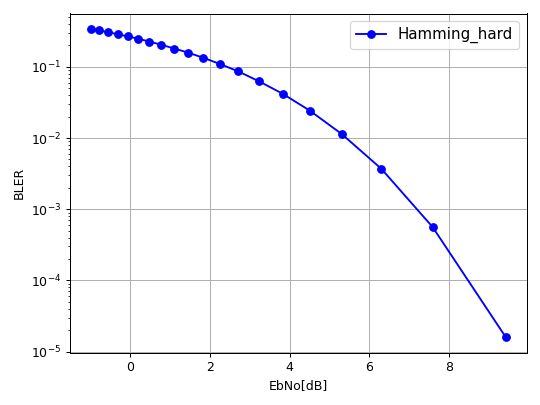)

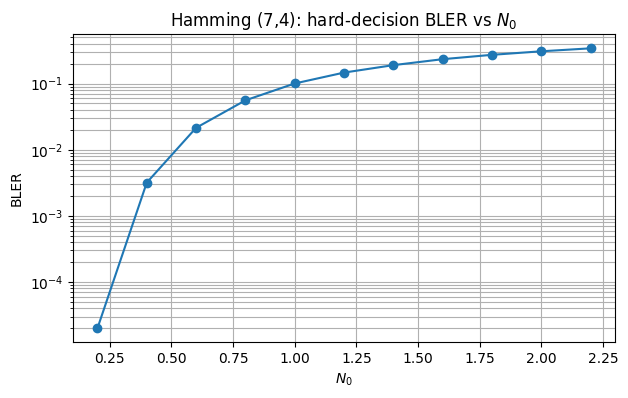

In [6]:
# Hamming (7,4) BLER versus No (linear scale as specified in the lab).
No_arr = np.arange(0.2, 2.21, 0.2)
N_sweep = 100_000
ham_bler = []
for No_i in No_arr:
    msg = rng.integers(0, 2, size=(N_sweep, 4))
    rx = awgn(bpsk(encode_hamming(msg)), No_i)
    dec = decode_hamming(rx)
    ham_bler.append(np.mean(np.any(msg != dec, axis=1)))
plt.figure(figsize=(7,4))
plt.semilogy(No_arr, np.maximum(ham_bler, 1/N_sweep), 'o-')
plt.xlabel('$N_0$'); plt.ylabel('BLER'); plt.title('Hamming (7,4): hard-decision BLER vs $N_0$')
plt.grid(True, which='both'); plt.show()


### What you concluded from the above plots ?

Ans:

## Bit Error Rate (BER)

-  Given input message sequence $m$ and decoded message sequence $\hat{m}$

- bit_err = $\sum_{i=1}^4 z_i$, where $z = [z_1 z_2 z_3 z_4] = (m + \hat{m})$ mod 2

- Count total bit errors when N_blocks = $10^6$ message sequences are tested

- Bit Error Rate (BER) = (Total number of errors) / (Total number of bits) = (Total number of errors) / ( k x N_blocks)

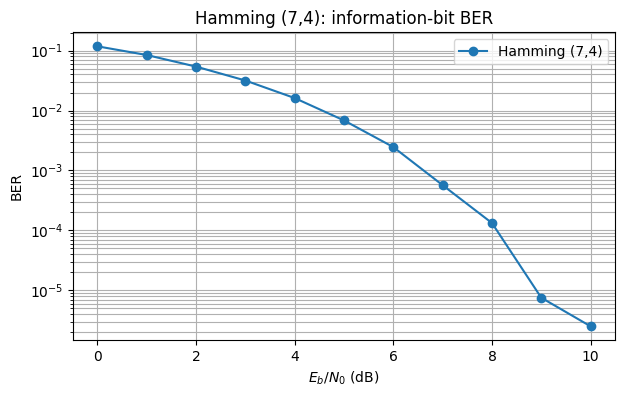

In [7]:
# Hamming (7,4) BER versus Eb/No, counting information-bit errors.
EbNo_dB_arr = np.arange(0, 11, 1)
N_sweep = 100_000
ham_ber = []
for ebno_db in EbNo_dB_arr:
    No_i = 7/4 / (10**(ebno_db/10))  # codeword energy 7 divided by k=4 bits
    msg = rng.integers(0, 2, size=(N_sweep, 4))
    rx = awgn(bpsk(encode_hamming(msg)), No_i)
    dec = decode_hamming(rx)
    ham_ber.append(np.mean(msg != dec))
plt.figure(figsize=(7,4))
plt.semilogy(EbNo_dB_arr, np.maximum(ham_ber, 1/(4*N_sweep)), 'o-', label='Hamming (7,4)')
plt.xlabel(r'$E_b/N_0$ (dB)'); plt.ylabel('BER'); plt.title('Hamming (7,4): information-bit BER')
plt.grid(True, which='both'); plt.legend(); plt.show()


## How to simulate and plot when EbNo[dB] values are given instead of No values? (Think)

### Given EbNo_dB_arr = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], simulate and plot EbNo_db vs BLER

### Your plot should look like below.

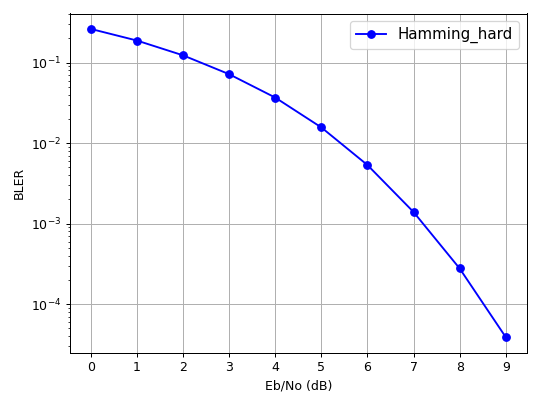

## Compare with Uncoded Case

- In uncoded case, message sequence $m$ is modulated and transmit to AWGN channel

- Decoded message $\hat{m}$ = demodulated sequence from received sequence $y$

- Eb = Energy per bit in uncoded case  =  1

- Plot EbNo_dB vs BER

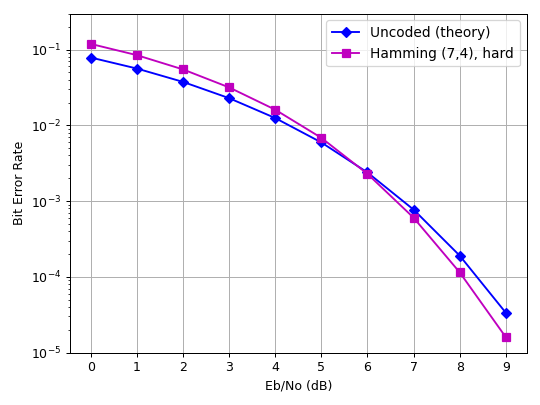

# Part 3: Uncoded vs Repetition (3, 1) vs Hamming (7, 4)

- Using hard decision decoding for both codes, plot EbNo_dB vs BER of the uncoded BPSK, the repetition (3, 1) code and the Hamming (7, 4) code on the same axes for EbNo_dB_arr = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] (y-axis in log scale)

- Eb for each scheme: uncoded $= 1$, repetition $= n/k = 3$, Hamming $= n/k = 7/4$ (energy per coded bit is 1 in every case)

- Your plot should look like below.

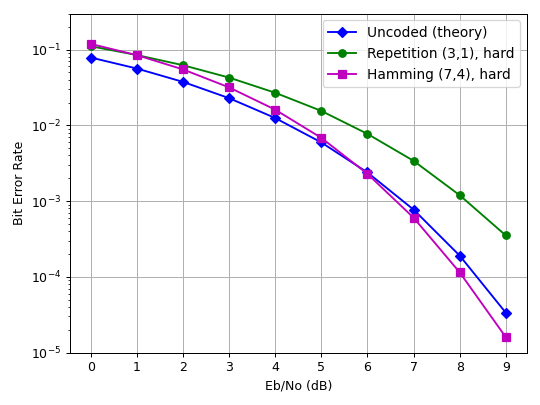

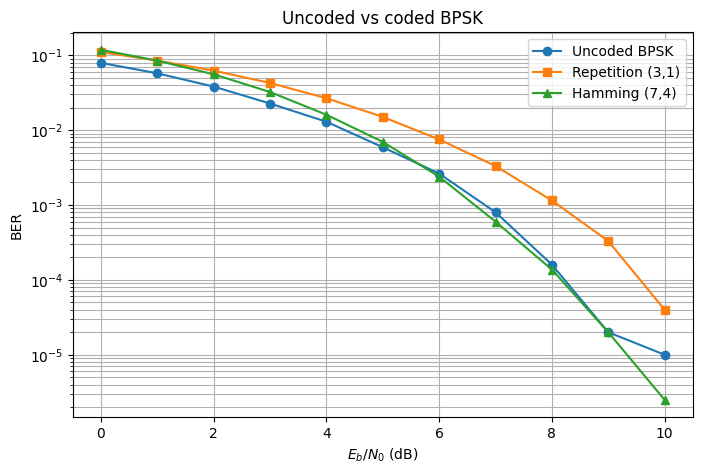

In [8]:
# Compare uncoded BPSK, repetition (3,1), and Hamming (7,4) at equal Eb/No.
EbNo_dB_arr = np.arange(0, 11, 1)
N_sweep = 100_000
uncoded_ber, repetition_ber, hamming_ber = [], [], []
for ebno_db in EbNo_dB_arr:
    ebno = 10**(ebno_db/10)
    # Uncoded BPSK: Eb=1
    msg = rng.integers(0, 2, N_sweep)
    uncoded_ber.append(np.mean(hard_decision(awgn(bpsk(msg), 1/ebno)) != msg))
    # Coded systems: keep information-bit energy normalization fair.
    msg_r = rng.integers(0, 2, N_sweep)
    rx_r = awgn(bpsk(encode_repetition(msg_r)), 3/ebno)
    repetition_ber.append(np.mean(decode_repetition(rx_r) != msg_r))
    msg_h = rng.integers(0, 2, size=(N_sweep, 4))
    rx_h = awgn(bpsk(encode_hamming(msg_h)), (7/4)/ebno)
    hamming_ber.append(np.mean(decode_hamming(rx_h) != msg_h))
plt.figure(figsize=(8,5))
plt.semilogy(EbNo_dB_arr, np.maximum(uncoded_ber, 1/N_sweep), 'o-', label='Uncoded BPSK')
plt.semilogy(EbNo_dB_arr, np.maximum(repetition_ber, 1/N_sweep), 's-', label='Repetition (3,1)')
plt.semilogy(EbNo_dB_arr, np.maximum(hamming_ber, 1/(4*N_sweep)), '^-', label='Hamming (7,4)')
plt.xlabel(r'$E_b/N_0$ (dB)'); plt.ylabel('BER'); plt.title('Uncoded vs coded BPSK')
plt.grid(True, which='both'); plt.legend(); plt.show()


### What you concluded from the above plot ?

Ans:

### Both codes have $d_{min} = 3$ and correct one error. Why do they give different BER at the same Eb/No?

Ans:

### Did you explore any other rates of coding then mentioned here, how did it effect the results? detail.

Ans:

### ONCE THE ABOVE SIMULATION IS COMPLETE, YOU SHALL NOW EXPERIMENT WITH THESE CODING OVER SDR AND ADD THE CODE, DETAILS OF THE EXPERIMENT, AND THE RESULTS OF BOTH CODING BELOW HERE. 

YOU ARE FREE TO CHOOSE YOUR COMMUNICATION CHAIN AND ITS COMPONENTS.

# Part 4A: Software-only BPSK simulation (no PlutoSDR required)

Run this section first to verify the message-to-bits mapping, BPSK modulation, pulse shaping, AWGN channel, matched filtering, hard decisions, BER, and plots **without connecting any SDR hardware**. The same message, `HELLO FROM LAB9!`, is used by the SDR section. Pulse shapes are energy-normalized in this software experiment so the Eb/N0 comparison is fair. The hardware experiment below retains the Lab 8 SDR flow.

Transmitted simulation message: HELLO FROM LAB9!
Message length: 16 bytes; 128 bits
First 32 bits: [0 1 0 0 1 0 0 0 0 1 0 0 0 1 0 1 0 1 0 0 1 1 0 0 0 1 0 0 1 1 0 0]


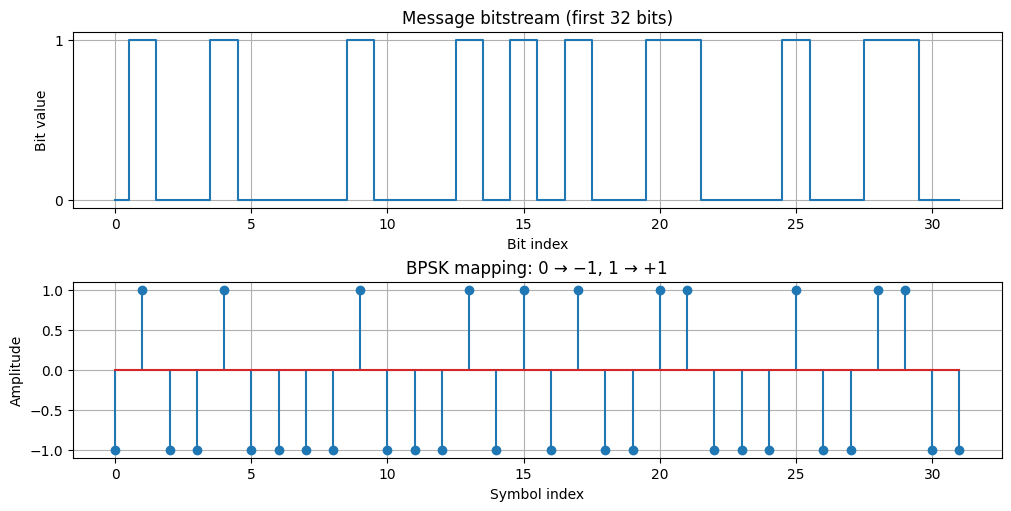

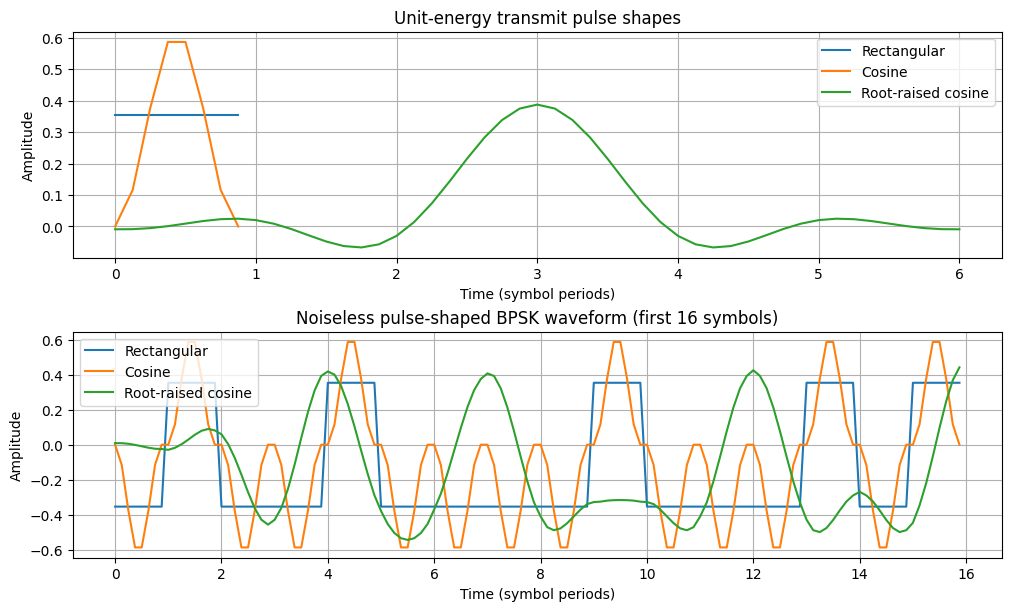


Noise-free software simulation
Rectangular         : errors=0/128, BER=0.000000, message='HELLO FROM LAB9!'
Cosine              : errors=0/128, BER=0.000000, message='HELLO FROM LAB9!'
Root-raised cosine  : errors=0/128, BER=0.000000, message='HELLO FROM LAB9!'


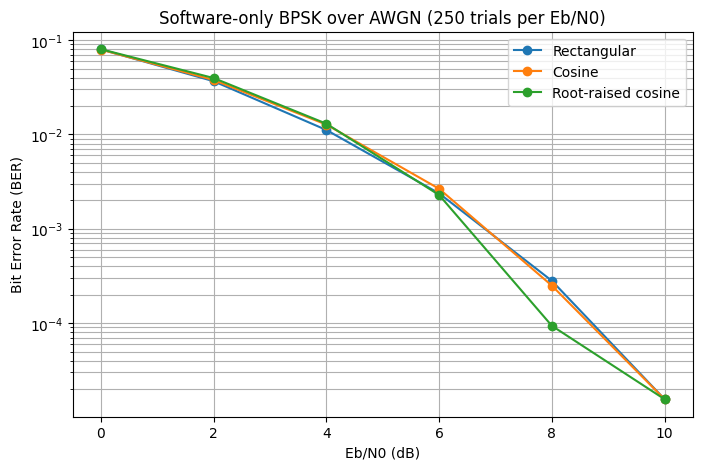


Measured software BER (finite Monte Carlo run)
Eb/N0 (dB)           Rectangular                Cosine    Root-raised cosine
       0.0             0.0798438             0.0793125              0.080125
       2.0             0.0366875             0.0378125              0.039625
       4.0             0.0111562             0.0127187                 0.013
       6.0              0.002375            0.00265625            0.00228125
       8.0            0.00028125               0.00025             9.375e-05
      10.0                     0                     0                     0


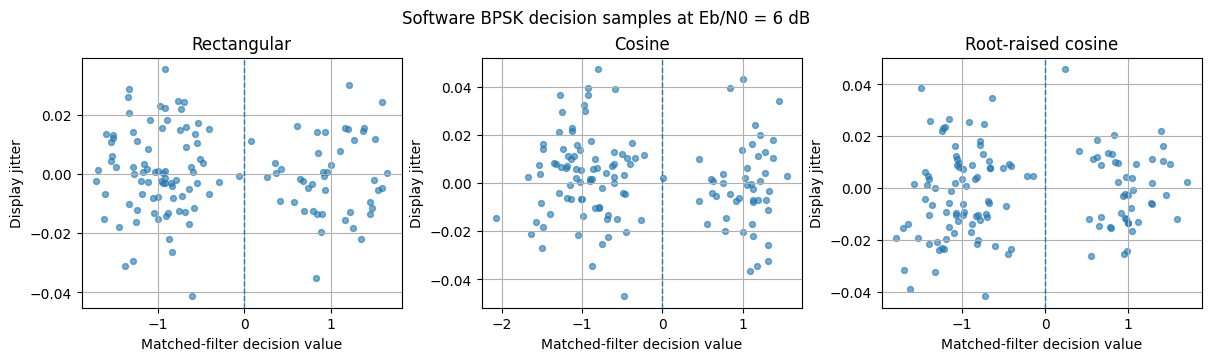

In [9]:
# Software-only simulation: standard-library NumPy/Matplotlib/SciPy only.
# This cell does not instantiate or communicate with a PlutoSDR.
import numpy as np
import matplotlib.pyplot as plt

SIM_MESSAGE = "HELLO FROM LAB9!"
SIM_BITS = np.unpackbits(
    np.frombuffer(SIM_MESSAGE.encode("utf-8"), dtype=np.uint8), bitorder="big"
).astype(np.int8)
SIM_SYMBOLS = (2 * SIM_BITS - 1).astype(float)  # 0 -> -1, 1 -> +1
SIM_SPS = 8
SIM_RNG = np.random.default_rng(2026)

print("Transmitted simulation message:", SIM_MESSAGE)
print(f"Message length: {len(SIM_MESSAGE.encode('utf-8'))} bytes; {len(SIM_BITS)} bits")
print("First 32 bits:", SIM_BITS[:32])

# Pulse shapes used by Lab 8. The RRC pulse is generated locally so this section
# is independently runnable before any SDR/hardware cells are executed.
def sim_rect_pulse(sps):
    return np.ones(sps, dtype=float)

def sim_cosine_pulse(sps):
    n = np.arange(sps)
    return 0.5 * (1 - np.cos(2 * np.pi * n / (sps - 1)))

def sim_rrc_pulse(sps, beta=0.35, span=6):
    n = np.arange(-span * sps // 2, span * sps // 2 + 1)
    t = n / sps
    h = np.zeros_like(t, dtype=float)
    if beta == 0:
        h = np.sinc(t)
    else:
        at_zero = np.isclose(t, 0.0, atol=1e-12)
        at_singular = np.isclose(np.abs(t), 1 / (4 * beta), atol=1e-12)
        general = ~(at_zero | at_singular)
        h[at_zero] = 1 + beta * (4 / np.pi - 1)
        h[at_singular] = (beta / np.sqrt(2) * (
            (1 + 2 / np.pi) * np.sin(np.pi / (4 * beta)) +
            (1 - 2 / np.pi) * np.cos(np.pi / (4 * beta))
        ))
        tg = t[general]
        h[general] = (
            np.sin(np.pi * tg * (1 - beta)) +
            4 * beta * tg * np.cos(np.pi * tg * (1 + beta))
        ) / (np.pi * tg * (1 - (4 * beta * tg) ** 2))
    return h

def sim_shape(symbols, pulse, sps):
    upsampled = np.zeros(len(symbols) * sps, dtype=float)
    upsampled[::sps] = symbols
    return np.convolve(upsampled, pulse, mode="full")

def sim_demod(rx_waveform, pulse, sps, n_symbols):
    # Matched filter. For this causal FIR pulse representation, the decision
    # peaks occur at len(pulse)-1 + k*sps.
    mf = np.convolve(rx_waveform, pulse[::-1], mode="full")
    decisions = mf[len(pulse)-1::sps][:n_symbols]
    return (decisions > 0).astype(np.int8), decisions

SIM_PULSES = {
    "Rectangular": sim_rect_pulse(SIM_SPS),
    "Cosine": sim_cosine_pulse(SIM_SPS),
    "Root-raised cosine": sim_rrc_pulse(SIM_SPS, beta=0.35, span=6),
}
# Normalize each pulse to unit energy to compare them at equal Eb/N0.
SIM_PULSES = {name: pulse / np.sqrt(np.sum(pulse**2)) for name, pulse in SIM_PULSES.items()}

# Plot the message bits and its BPSK symbols.
fig, ax = plt.subplots(2, 1, figsize=(10, 5), constrained_layout=True)
show_n = min(32, len(SIM_BITS))
ax[0].step(np.arange(show_n), SIM_BITS[:show_n], where="mid")
ax[0].set_title("Message bitstream (first 32 bits)")
ax[0].set_xlabel("Bit index"); ax[0].set_ylabel("Bit value")
ax[0].set_yticks([0, 1]); ax[0].grid(True)
ax[1].stem(np.arange(show_n), SIM_SYMBOLS[:show_n])
ax[1].set_title("BPSK mapping: 0 → −1, 1 → +1")
ax[1].set_xlabel("Symbol index"); ax[1].set_ylabel("Amplitude")
ax[1].grid(True)
plt.show()

# Plot each pulse in time and the corresponding noiseless shaped waveform.
fig, ax = plt.subplots(2, 1, figsize=(10, 6), constrained_layout=True)
for name, pulse in SIM_PULSES.items():
    ax[0].plot(np.arange(len(pulse)) / SIM_SPS, pulse, label=name)
    waveform = sim_shape(SIM_SYMBOLS[:16], pulse, SIM_SPS)
    ax[1].plot(np.arange(min(len(waveform), 16 * SIM_SPS)) / SIM_SPS,
               waveform[:16 * SIM_SPS], label=name)
ax[0].set_title("Unit-energy transmit pulse shapes")
ax[0].set_xlabel("Time (symbol periods)"); ax[0].set_ylabel("Amplitude")
ax[1].set_title("Noiseless pulse-shaped BPSK waveform (first 16 symbols)")
ax[1].set_xlabel("Time (symbol periods)"); ax[1].set_ylabel("Amplitude")
for a in ax: a.grid(True); a.legend()
plt.show()

# Noise-free end-to-end check: every bit should be recovered exactly.
print("\nNoise-free software simulation")
for name, pulse in SIM_PULSES.items():
    tx_wave = sim_shape(SIM_SYMBOLS, pulse, SIM_SPS)
    rx_bits, rx_decisions = sim_demod(tx_wave, pulse, SIM_SPS, len(SIM_BITS))
    errors = int(np.count_nonzero(SIM_BITS != rx_bits))
    ber = errors / len(SIM_BITS)
    rx_message = np.packbits(rx_bits, bitorder="big").tobytes().decode("utf-8", errors="replace")
    print(f"{name:20s}: errors={errors}/{len(SIM_BITS)}, BER={ber:.6f}, message={rx_message!r}")
    assert errors == 0, f"Noise-free {name} simulation did not recover every bit."

# AWGN simulation: Eb/N0 is swept, with complex-equivalent real baseband noise.
# Pulse energy is one, so the matched-filter sample has Eb=1. Real noise variance
# per sample is N0/2, where N0 = Eb / (Eb/N0).
SIM_EBN0_DB = np.arange(0, 11, 2)
SIM_N_TRIALS = 250
SIM_BER = {name: [] for name in SIM_PULSES}
SIM_RNG = np.random.default_rng(2026)

for ebn0_db in SIM_EBN0_DB:
    gamma = 10 ** (ebn0_db / 10)
    n0 = 1.0 / gamma
    noise_sigma = np.sqrt(n0 / 2)
    error_counts = {name: 0 for name in SIM_PULSES}
    total_bits = 0
    for _ in range(SIM_N_TRIALS):
        bits = SIM_RNG.integers(0, 2, len(SIM_BITS), dtype=np.int8)
        symbols = (2 * bits - 1).astype(float)
        for name, pulse in SIM_PULSES.items():
            tx_wave = sim_shape(symbols, pulse, SIM_SPS)
            noisy_wave = tx_wave + SIM_RNG.normal(0, noise_sigma, size=len(tx_wave))
            rx_bits, _ = sim_demod(noisy_wave, pulse, SIM_SPS, len(bits))
            error_counts[name] += int(np.count_nonzero(bits != rx_bits))
        total_bits += len(SIM_BITS)
    for name in SIM_PULSES:
        SIM_BER[name].append(error_counts[name] / total_bits)

plt.figure(figsize=(8, 5))
for name, values in SIM_BER.items():
    # A BER of zero can occur at high SNR for finite Monte Carlo runs; plot it at
    # a small display floor without changing the printed measurement.
    plotted = np.maximum(values, 0.5 / (SIM_N_TRIALS * len(SIM_BITS)))
    plt.semilogy(SIM_EBN0_DB, plotted, marker="o", label=name)
plt.xlabel("Eb/N0 (dB)"); plt.ylabel("Bit Error Rate (BER)")
plt.title(f"Software-only BPSK over AWGN ({SIM_N_TRIALS} trials per Eb/N0)")
plt.grid(True, which="both"); plt.legend(); plt.show()

print("\nMeasured software BER (finite Monte Carlo run)")
print(f"{'Eb/N0 (dB)':>10}  " + "  ".join(f"{name:>20}" for name in SIM_PULSES))
for i, snr in enumerate(SIM_EBN0_DB):
    print(f"{snr:10.1f}  " + "  ".join(f"{SIM_BER[name][i]:20.6g}" for name in SIM_PULSES))

# Illustrative noisy constellation at one selected Eb/N0 for the message payload.
example_db = 6
n0 = 10 ** (-example_db / 10)
noise_sigma = np.sqrt(n0 / 2)
fig, axes = plt.subplots(1, len(SIM_PULSES), figsize=(12, 3.5), constrained_layout=True)
for ax, (name, pulse) in zip(axes, SIM_PULSES.items()):
    tx_wave = sim_shape(SIM_SYMBOLS, pulse, SIM_SPS)
    noisy_wave = tx_wave + SIM_RNG.normal(0, noise_sigma, size=len(tx_wave))
    _, decisions = sim_demod(noisy_wave, pulse, SIM_SPS, len(SIM_BITS))
    # The simulation is real-valued BPSK baseband; show decision samples with a
    # tiny vertical jitter solely to make overlapping points visible.
    jitter = SIM_RNG.normal(0, 0.015, len(decisions))
    ax.scatter(decisions, jitter, s=18, alpha=0.6)
    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_title(name); ax.set_xlabel("Matched-filter decision value")
    ax.set_ylabel("Display jitter"); ax.grid(True)
plt.suptitle(f"Software BPSK decision samples at Eb/N0 = {example_db} dB")
plt.show()


# Part 4: SDR experiment — BPSK with selectable error-control coding

This section retains the Lab 8 PlutoSDR/Barker/Costas-loop/pulse-shaping receiver flow and **integrates the Lab 9 repetition (3,1) and Hamming (7,4) codes into the actual SDR payload**. Select `SDR_CODE = "uncoded"`, `"repetition"`, or `"hamming74"` in the message/encoder cell. The transmitter sends the encoded bitstream; the receiver hard-decides the BPSK symbols, decodes the selected code, then reconstructs the text and reports both coded-bit and information-bit BER. The coding-theory/AWGN sections above remain as separate simulations too.

Run the hardware cells in order after connecting/configuring the two PlutoSDRs. Start with `RUN_SDR = False` until you are ready to transmit. The SDR hardware section is not executed by the software-only simulation.


### How coding is applied over the SDR link

The readable message is converted to information bits, encoded according to `SDR_CODE`, BPSK-modulated and transmitted with the existing Lab 8 Barker preamble and pulse-shaping chain. At the receiver, BPSK hard decisions are passed through the matching repetition majority decoder or Hamming (7,4) syndrome decoder before converting back to UTF-8. The notebook reports coded-bit BER (from the physical link) and information-bit BER (after decoding). The coding mode is selected in the encoder cell; rerun all cells from that point onward after changing it.


## Hardware Configuration

In [10]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import fftconvolve, welch
import adi

In [11]:
fs = int(0.6e6)                # Sample rate: 2.0 MHz
fc = int(2.4e9)              # RF carrier: 2.4 GHz (must be supported by both Pluto SDRs)

# --- Frame / waveform parameters -------------------------------------
sps              = 8             # samples per symbol
barker_code      = np.array([1, 1, 1, 1, 1, -1, -1, 1, 1, -1, 1, -1, 1], dtype=np.float32)  # Barker-13
preamble_len     = len(barker_code) * sps  # sample count: each Barker chip lasts sps samples
preamble_scale   = 1.5           # preamble amplitude, relative to the payload's unit-average
                                  # symbols
MESSAGE = "HELLO FROM LAB9!"
n_bits_per_frame = len(MESSAGE.encode("utf-8")) * 8  # one BPSK symbol per message bit
tx_scale         = 2**14         # DAC full-scale headroom

# --- Raised-cosine pulse parameters (used starting in Part 2) --------
rc_beta = 0.35    # roll-off factor: 0 = narrowest possible bandwidth, slowest-decaying tails;
                  # 1 = widest bandwidth, fastest-decaying tails
rc_span = 6       # how many symbol periods the raised-cosine pulse extends across in total
                  # (3 on either side of its center)

# Connect to the two independent Pluto SDRs
tx_sdr = adi.Pluto("ip:192.168.2.1")
# rx_sdr = adi.Pluto("ip:192.168.3.1")

#################################################
# Config TX
tx_sdr.sample_rate = fs
tx_sdr.tx_lo = fc
tx_sdr.tx_rf_bandwidth = fs
tx_sdr.tx_hardwaregain_chan0 = -40   # dB of attenuation from full scale -- a starting point;
                                      # Task 6 and Task 11 will set this explicitly
tx_sdr.tx_cyclic_buffer = True       # loops the frame so the RX side can't miss it entirely

##########################################
# # Config RX
# rx_sdr.sample_rate = fs
# rx_sdr.rx_lo = fc
# rx_sdr.rx_rf_bandwidth = fs
# rx_sdr.gain_control_mode_chan0 = "manual"
# rx_sdr.rx_hardwaregain_chan0 = 30    # dB, fixed for the whole lab -- every BER comparison in
#                                       # this notebook uses the same receiver operating point,
#                                       # so differences you see come from the pulse shape, not
#                                       # a moving receiver gain

In [12]:
rx_sdr = adi.Pluto("ip:192.168.3.1")

rx_sdr.sample_rate = fs
rx_sdr.rx_lo = fc
rx_sdr.rx_rf_bandwidth = fs
rx_sdr.gain_control_mode_chan0 = "manual"
rx_sdr.rx_hardwaregain_chan0 = 30  

Before doing anything else, it's worth a quick look at what the receiver sees with
nothing deliberately being transmitted -- a basic calibration habit worth keeping regardless
of what the rest of the lab does with the signal.

In [13]:
# Quick calibration check: a short idle capture, no frame in flight. If this power
# looks unreasonably high, sort that out before trusting anything downstream.
rx_sdr.rx_buffer_size = 4096
idle_samples = rx_sdr.rx()
idle_power_db = 10 * np.log10(np.mean(np.abs(idle_samples) ** 2))
print(f"Idle noise floor: {idle_power_db:.1f} dB (power, arbitrary units)")

Idle noise floor: 9.1 dB (power, arbitrary units)


## BPSK Constellation and Bit Mapping

This lab only uses BPSK -- the pulse shape is what's changing, not the modulation -- so the
constellation and the generic bit-mapping helpers are given below rather than re-derived.
`bits_to_symbols` / `symbols_to_bits` read out of `CONSTELLATIONS` / `BITS_PER_SYMBOL`, which
keeps them reusable even though this lab only ever registers one scheme.

In [14]:
CONSTELLATIONS = {
    'BPSK': {'0': -1 + 0j, '1': 1 + 0j},
}
BITS_PER_SYMBOL = {
    'BPSK': 1,
}

def bits_to_symbols(bits, scheme):
    k = BITS_PER_SYMBOL[scheme]
    n_symbols = len(bits) // k
    used_bits = bits[:n_symbols * k]
    groups = used_bits.reshape(n_symbols, k)
    labels = [''.join(str(b) for b in row) for row in groups]
    symbols = np.array([CONSTELLATIONS[scheme][lbl] for lbl in labels], dtype=np.complex64)
    return symbols, used_bits


def symbols_to_bits(rx_symbols, scheme):
    labels = list(CONSTELLATIONS[scheme].keys())
    ideal_points = np.array(list(CONSTELLATIONS[scheme].values()))
    dists = np.abs(rx_symbols[:, None] - ideal_points[None, :])
    winners = np.argmin(dists, axis=1)
    bits = np.array([[int(b) for b in labels[w]] for w in winners]).flatten()
    return bits

## Task 1: Convert a Readable Message to Bits

Generate the one fixed bit sequence this lab will reuse for every transmission -- rectangular,
cosine, and raised-cosine alike -- so the comparison at the end is on equal footing.

In [15]:
# Message source and error-control coding used by the ACTUAL SDR payload.
# Each UTF-8 byte is sent MSB-first. Choose: "uncoded", "repetition", or "hamming74".
SDR_CODE = "hamming74"


def message_to_bits(text):
    payload = text.encode("utf-8")
    return np.unpackbits(np.frombuffer(payload, dtype=np.uint8), bitorder="big").astype(np.int8)


def bits_to_message(bits):
    bits = np.asarray(bits, dtype=np.uint8).ravel()
    n_complete_bytes = len(bits) // 8
    payload = np.packbits(bits[:n_complete_bytes * 8], bitorder="big").tobytes()
    return payload.decode("utf-8", errors="replace")


def repetition_encode(bits):
    """Repetition (3,1): transmit each information bit three times."""
    return np.repeat(np.asarray(bits, dtype=np.int8).ravel(), 3)


def repetition_decode(bits):
    """Hard-decision majority vote for repetition (3,1)."""
    b = np.asarray(bits, dtype=np.int8).ravel()
    n = (len(b) // 3) * 3
    if n == 0:
        return np.array([], dtype=np.int8)
    triples = b[:n].reshape(-1, 3)
    return (np.sum(triples, axis=1) >= 2).astype(np.int8)


def hamming74_encode(bits):
    """Hamming (7,4), even parity, codeword positions [p1,p2,d1,p4,d2,d3,d4].
    Returns (encoded_bits, number_of_pad_bits).
    """
    b = np.asarray(bits, dtype=np.int8).ravel()
    pad = (-len(b)) % 4
    if pad:
        b = np.concatenate([b, np.zeros(pad, dtype=np.int8)])
    m = b.reshape(-1, 4)
    d1, d2, d3, d4 = m[:, 0], m[:, 1], m[:, 2], m[:, 3]
    p1 = d1 ^ d2 ^ d4
    p2 = d1 ^ d3 ^ d4
    p4 = d2 ^ d3 ^ d4
    c = np.column_stack([p1, p2, d1, p4, d2, d3, d4]).astype(np.int8)
    return c.reshape(-1), pad


def hamming74_decode(bits):
    """Hard-decision Hamming (7,4) syndrome decoder; corrects one bit per codeword."""
    b = np.asarray(bits, dtype=np.int8).ravel()
    n = (len(b) // 7) * 7
    if n == 0:
        return np.array([], dtype=np.int8)
    words = b[:n].reshape(-1, 7).copy()
    # Syndrome checks for positions [p1,p2,d1,p4,d2,d3,d4].
    s1 = words[:, 0] ^ words[:, 2] ^ words[:, 4] ^ words[:, 6]
    s2 = words[:, 1] ^ words[:, 2] ^ words[:, 5] ^ words[:, 6]
    s4 = words[:, 3] ^ words[:, 4] ^ words[:, 5] ^ words[:, 6]
    syndrome = s1 + 2 * s2 + 4 * s4
    for row, syn in enumerate(syndrome):
        if syn:
            words[row, int(syn) - 1] ^= 1
    return words[:, [2, 4, 5, 6]].reshape(-1)


def encode_sdr_payload(info_bits, mode):
    if mode == "uncoded":
        return np.asarray(info_bits, dtype=np.int8).copy(), 0
    if mode == "repetition":
        return repetition_encode(info_bits), 0
    if mode == "hamming74":
        return hamming74_encode(info_bits)
    raise ValueError("SDR_CODE must be 'uncoded', 'repetition', or 'hamming74'")


def decode_sdr_payload(coded_bits, mode, info_length, hamming_pad=0):
    if mode == "uncoded":
        decoded = np.asarray(coded_bits, dtype=np.int8).ravel()
    elif mode == "repetition":
        decoded = repetition_decode(coded_bits)
    elif mode == "hamming74":
        decoded = hamming74_decode(coded_bits)
        if hamming_pad:
            decoded = decoded[:-hamming_pad]
    else:
        raise ValueError("Unknown SDR coding mode: " + str(mode))
    return decoded[:info_length]


MESSAGE = "HELLO AI"
tx_info_bits = message_to_bits(MESSAGE)
tx_bits, hamming_pad_bits = encode_sdr_payload(tx_info_bits, SDR_CODE)
# Update this frame-length metadata to match the encoded SDR payload.
n_bits_per_frame = len(tx_bits)
print("Transmitted message:", MESSAGE)
print("SDR coding mode:", SDR_CODE)
print(f"Information payload: {len(tx_info_bits)} bits")
print(f"Encoded SDR payload: {len(tx_bits)} bits")
if SDR_CODE == "hamming74":
    print(f"Hamming padding bits: {hamming_pad_bits}")
print("First 32 transmitted payload bits:", tx_bits[:32])

# Local round-trip checks: validate encoder/decoder mapping before using hardware.
for _mode in ("uncoded", "repetition", "hamming74"):
    _coded, _pad = encode_sdr_payload(tx_info_bits, _mode)
    _decoded = decode_sdr_payload(_coded, _mode, len(tx_info_bits), _pad)
    assert np.array_equal(_decoded, tx_info_bits), f"{_mode} encode/decode self-test failed"
print("Uncoded, repetition, and Hamming SDR coding self-tests passed.")


Transmitted message: HELLO AI
SDR coding mode: hamming74
Information payload: 64 bits
Encoded SDR payload: 112 bits
Hamming padding bits: 0
First 32 transmitted payload bits: [1 0 0 1 1 0 0 1 1 1 0 0 0 0 1 0 0 1 1 0 0 0 1 0 0 1 0 1 1 0 0 1]
Uncoded, repetition, and Hamming SDR coding self-tests passed.


## Part 1: A Smoother Alternative -- the Cosine Pulse

A quick note on naming before starting: "raised cosine" gets used for two different things in
this field, which trips people up constantly. The taper you're about to build in Task 2 is
sometimes casually called a "raised-cosine window" -- and it does look like one -- but that's
a different animal from the "raised-cosine pulse" in Part 2, which is a specific pulse
designed to satisfy Nyquist's zero-ISI criterion. To keep the two straight, this lab just
calls the first one **the cosine pulse**, full stop, and saves "raised cosine" for Part 2.

## Task 2: The Cosine Pulse

The rectangular pulse jumps from 0 to its full value instantly at the start of every symbol,
and back down just as abruptly at the end. The cosine pulse replaces both jumps with a smooth
taper that touches exactly zero at both edges and rises to its peak in the middle:

$$g[n] = \tfrac{1}{2}\left(1 - \cos\left(\dfrac{2\pi n}{\text{sps} - 1}\right)\right), \qquad
n = 0, 1, \dots, \text{sps}-1$$

`cosine_pulse(sps)` below builds this as an array. Your one job is the formula itself --
`np.arange(sps)` already gives you `n = 0, 1, ..., sps-1`, so the rest is a direct
translation of the equation above into NumPy.

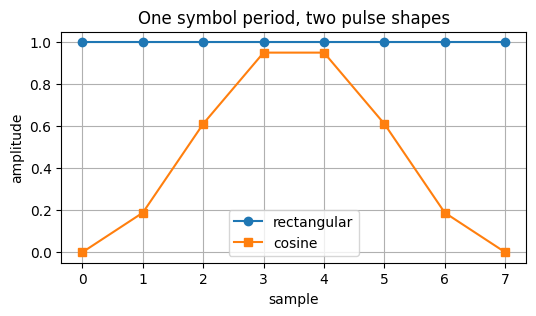

In [16]:
def rect_pulse(sps):
    '''The rectangular pulse: sps samples, all equal to 1.'''
    return np.ones(sps)


def cosine_pulse(sps):
    '''
    TODO: one line, following the formula above. n is given.
    '''
    n = np.arange(sps)
    pulse = 0.5 * (1 - np.cos(2 * np.pi * n / (sps - 1)))
    return pulse


plt.figure(figsize=(6, 3))
plt.plot(rect_pulse(sps), 'o-', label='rectangular')
plt.plot(cosine_pulse(sps), 's-', label='cosine')
plt.xlabel('sample')
plt.ylabel('amplitude')
plt.title("One symbol period, two pulse shapes")
plt.legend()
plt.grid(True)
plt.show()

## Task 3: General Pulse Shaping and Matched Filtering

Rather than writing separate shaping code for each pulse, it's worth building this once in a
form that works for *any* pulse you hand it -- rectangular, cosine, or (in Part 2) something
much longer. `pulse_shape(symbols, pulse, sps)` does this by zero-stuffing your symbols (one
nonzero sample every `sps` samples, matching each symbol's timing) and convolving the result
with the pulse -- given below in full, since it's the same idea regardless of pulse shape.

`matched_filter_downsample(samples, pulse, sps)` is the receive-side counterpart: correlate
against the *matched* kernel (the pulse, reversed and conjugated), then keep one output sample
per symbol. Your one job is the kernel itself:

$$\text{kernel} = \dfrac{\text{conj}(\text{pulse reversed})}{\sum |\text{pulse}|^2}$$

The denominator matters: without it, the matched filter's output would be scaled by the
pulse's own energy instead of landing back on the transmitted symbol's actual amplitude.

Important timing detail: `pulse_shape` uses full convolution, so the receive filter must
compensate the combined pulse delay exactly. One detail that's easy to miss and worth stating
plainly: the downsampling index below is
`len(pulse) - 1`, not `sps - 1`. For the rectangular and cosine pulses those are the same
number, since both pulses are exactly `sps` samples long -- but Part 2's raised-cosine pulse
will be much longer than one symbol period, and this same formula (and the same two
functions) will still work correctly, unchanged, once you get there.

**Timing convention:** the transmitter uses full convolution. The matched-filter peak for the first symbol occurs at `len(pulse)-1` samples after the payload starts, so the downsampler starts there. For long RRC pulses, the waveform and capture must include the filter tail.


In [17]:
def pulse_shape(symbols, pulse, sps):
    n_symbols = len(symbols)
    zero_stuffed = np.zeros(n_symbols * sps, dtype=complex)
    zero_stuffed[0::sps] = symbols
    shaped = np.convolve(zero_stuffed, pulse)   # full convolution -- keep every sample,
                                                  # including the tail past the last symbol
                                                  # (matters once pulses get longer than one
                                                  # symbol period, in Part 2)
    return shaped


def matched_filter_downsample(samples, pulse, sps):
    '''
    TODO: one line. kernel = conj(reversed pulse) / (pulse energy) -- see the formula above.
    '''
    kernel = np.conj(pulse[::-1]) / np.sum(np.abs(pulse) ** 2)
    filtered = np.convolve(samples, kernel)
    delay = len(pulse) - 1
    # The first valid symbol decision occurs at the matched-filter peak delay.
    # For a pulse of length L, that peak is at L-1 in the full convolution.
    return filtered[delay::sps]


# Sanity check: shape a few symbols with the cosine pulse, matched-filter them back, and
# confirm you recover (approximately) the original symbol values.
test_symbols = np.array([1 + 0j, -1 + 0j, 1 + 0j, -1 + 0j])
test_pulse = cosine_pulse(sps)
shaped = pulse_shape(test_symbols, test_pulse, sps)
recovered = matched_filter_downsample(shaped, test_pulse, sps)
print("Transmitted:", test_symbols)
print("Recovered:  ", np.round(recovered[:len(test_symbols)], 3))
assert np.allclose(recovered[:len(test_symbols)], test_symbols, atol=1e-6), \
    "Matched-filter timing/normalization is incorrect for this pulse."

Transmitted: [ 1.+0.j -1.+0.j  1.+0.j -1.+0.j]
Recovered:   [ 1.+0.j -1.+0.j  1.+0.j -1.+0.j]


## Task 4: Frame Construction, Transmit, and Capture

The frame begins with a **Barker-13 training sequence**. Each of the 13 chips (+1/-1) is held for `sps` samples, giving a known sample-level template for normalized correlation-based frame detection and channel/CFO estimation. The pulse-shaped BPSK payload follows the preamble.

In [18]:
def make_barker_preamble(sps, scale):
    """Barker-13 known training sequence, each chip held for sps samples."""
    chips = np.asarray(barker_code, dtype=np.complex64)
    return (np.repeat(chips, sps) * scale).astype(np.complex64)


def build_tx_frame(bits, pulse, sps, preamble_len, preamble_scale):
    data_symbols, used_bits = bits_to_symbols(bits, 'BPSK')
    payload = pulse_shape(data_symbols, pulse, sps)

    preamble = make_barker_preamble(sps, preamble_scale)
    if len(preamble) != preamble_len:
        raise ValueError(f"Barker preamble length mismatch: {len(preamble)} != {preamble_len}")

    frame = np.concatenate([preamble, payload]).astype(np.complex64) * tx_scale
    return frame, used_bits


def frame_len_for(n_symbols, pulse_len, preamble_len, sps):
    # Preamble is a known sample sequence; payload is causal pulse-shaped data.
    return preamble_len + n_symbols * sps + pulse_len - 1


def buffer_size_for(frame_len, margin=2.2):
    return int(np.ceil(margin * frame_len))


def capture(tx_frame, buffer_size, settle=0.5, flush=5):
    rx_sdr.rx_buffer_size = buffer_size
    try:
        tx_sdr.tx_destroy_buffer()
    except Exception:
        pass
    tx_sdr.tx(tx_frame)
    time.sleep(settle)
    for _ in range(flush):
        _ = rx_sdr.rx()
    rx_samples = np.asarray(rx_sdr.rx()).ravel()
    if len(rx_samples) < buffer_size:
        print(
            f"WARNING: Pluto returned {len(rx_samples)} samples, but {buffer_size} were requested. "
            "Frame length must fit in the actual capture."
        )
    return rx_samples


# Demo: build one BPSK frame using the cosine pulse, transmit, capture
cos_pulse_arr = cosine_pulse(sps)
demo_frame, demo_used_bits = build_tx_frame(tx_bits, cos_pulse_arr, sps, preamble_len, preamble_scale)
demo_frame_len = frame_len_for(len(demo_used_bits), len(cos_pulse_arr), preamble_len, sps)
print("Barker-13 preamble samples:", preamble_len, "sample rate:", fs)


Barker-13 preamble samples: 104 sample rate: 600000


## Task 5: Frame Synchronization and Correction

The preamble is a constant complex tone (one repeated sample value), so a carrier-frequency offset rotates its phase from sample to sample. A plain coherent sum can fail when that phase rotates. `find_frame_start` therefore uses adjacent-sample differential phase coherence, which is robust to a constant CFO. It searches only positions where the full frame fits in the capture.

`correct_frame` estimates CFO from the preamble's adjacent-sample phase increment, removes it, and then estimates preamble phase and amplitude. The BER routine now refuses to silently truncate unequal bit arrays.

**Important:** restart the kernel and run every cell from the top. Old notebook state can otherwise mix 120,000 old TX bits with a newly configured short frame.

**Fine carrier tracking:** after coarse CFO/phase correction and matched filtering, a symbol-rate BPSK Costas loop tracks residual phase/frequency drift. Preamble-based correction is still needed for coarse acquisition and to resolve BPSK's 180-degree phase ambiguity.


In [19]:
def find_frame_start(rx_samples, preamble_len, frame_len, search_stride=None):
    """Find the known Barker-13 sample pattern by normalized complex correlation."""
    x = np.asarray(rx_samples).ravel().astype(np.complex128)
    template = make_barker_preamble(sps, preamble_scale).astype(np.complex128)
    if len(template) != preamble_len:
        raise ValueError("Barker template length does not match preamble_len.")
    if frame_len > len(x):
        raise ValueError(f"Capture too short: {len(x)} samples, frame requires {frame_len}.")

    # Matched correlation, normalized by local receive energy to reduce gain sensitivity.
    corr = fftconvolve(x, np.conj(template[::-1]), mode="valid")
    energy = fftconvolve(np.abs(x)**2, np.ones(len(template)), mode="valid").real
    template_energy = np.sum(np.abs(template)**2)
    score = np.abs(corr) / np.sqrt(np.maximum(energy * template_energy, 1e-20))

    # Require the entire frame to fit in the capture.
    max_start = len(x) - frame_len
    score[max_start + 1:] = -np.inf
    start = int(np.argmax(score))
    if not np.isfinite(score[start]) or score[start] < 0.2:
        raise ValueError(
            f"Barker preamble correlation too low (score={score[start]:.3f}). "
            "Check TX/RX frequency, gain, capture length and timing."
        )
    print(f"Barker sync correlation={score[start]:.3f}")
    return start


def correct_frame(frame_slice, preamble_len, preamble_symbol, preamble_scale, fs):
    """Use known Barker samples for coarse CFO, phase and gain correction."""
    x = np.asarray(frame_slice).ravel().astype(np.complex128)
    template = make_barker_preamble(sps, preamble_scale).astype(np.complex128)
    if len(x) <= preamble_len or len(template) != preamble_len:
        raise ValueError("Frame/preamble length mismatch or no payload after preamble.")

    pre = x[:preamble_len]
    # Divide out the known Barker waveform. Its phase transitions are removed,
    # leaving the carrier's approximately linear phase progression.
    valid = np.abs(template) > 1e-12
    ratio = pre[valid] / template[valid]
    sample_idx = np.flatnonzero(valid).astype(float)
    phase_unwrapped = np.unwrap(np.angle(ratio))
    # Least-squares slope is less noisy than adjacent-sample phase estimates.
    slope, intercept = np.polyfit(sample_idx, phase_unwrapped, 1)
    f_offset_hat = slope * fs / (2 * np.pi)

    n = np.arange(len(x), dtype=float)
    cfo_corrected = x * np.exp(-1j * 2 * np.pi * f_offset_hat * n / fs)
    pre_corrected = cfo_corrected[:preamble_len]
    ref_ratio = pre_corrected[valid] / template[valid]
    channel = np.mean(ref_ratio)
    if abs(channel) < 1e-12:
        raise ValueError("Barker channel estimate is near zero.")
    phase_offset_hat = np.angle(channel)
    gain_hat = np.abs(channel)
    corrected = cfo_corrected / channel
    return corrected, f_offset_hat, phase_offset_hat, gain_hat


In [20]:
# Receiver sanity checks: run_trial prints sync/CFO/phase/gain and enforces exact BER lengths.
# Barker-13 synchronization prints its normalized correlation score. If BER remains near 0.5, inspect this score, CFO/gain estimates, constellation, TX/RX LO and RF gain.
print("Current configuration:")
print(f"fs={fs}, sps={sps}, preamble_len={preamble_len}, n_bits_per_frame={n_bits_per_frame}")
print("BPSK mapping: 0 -> -1, 1 -> +1")


Current configuration:
fs=600000, sps=8, preamble_len=104, n_bits_per_frame=112
BPSK mapping: 0 -> -1, 1 -> +1


## Task 6: Single-Frame BER With the Cosine Pulse

`compute_ber` and `run_trial` are given below -- `run_trial` wraps Tasks 3-5 into one
repeatable call: build a frame with whichever pulse you hand it, transmit at a given TX gain,
capture, sync, correct, matched-filter, and score. Your one job is the call itself.

In [21]:

def costas_loop_bpsk(symbols, loop_bandwidth=0.02, damping=0.707):
    """
    Symbol-rate decision-directed BPSK Costas loop for fine residual carrier
    phase/frequency tracking. Input must be matched-filtered and coarsely
    frequency/phase corrected. Returns corrected symbols and phase history.
    """
    x = np.asarray(symbols, dtype=np.complex128).ravel()
    if not len(x):
        return x.copy(), np.array([], dtype=float)

    zeta = float(damping)
    wn = float(loop_bandwidth) / (zeta + 1.0 / (4.0 * zeta))
    alpha = 2.0 * zeta * wn
    beta = wn * wn
    phase = 0.0
    freq = 0.0
    out = np.empty_like(x)
    phases = np.empty(len(x), dtype=float)

    for k, sample in enumerate(x):
        y = sample * np.exp(-1j * phase)
        out[k] = y
        phases[k] = phase
        scale = max(abs(y), 1e-12)
        error = np.sign(y.real) * y.imag / scale
        freq += beta * error
        phase += freq + alpha * error
        phase = (phase + np.pi) % (2 * np.pi) - np.pi

    return out, phases


def compute_ber(tx_bits, rx_bits):
    """Strict BER: never silently compare only a truncated prefix."""
    tx_bits = np.asarray(tx_bits).astype(int).ravel()
    rx_bits = np.asarray(rx_bits).astype(int).ravel()
    if len(tx_bits) != len(rx_bits):
        raise ValueError(
            f"BER comparison invalid: {len(tx_bits)} TX bits but {len(rx_bits)} RX bits. "
            "Check frame start, matched-filter delay, and payload extraction."
        )
    if len(tx_bits) == 0:
        raise ValueError("Cannot compute BER on an empty bit sequence.")
    errors = int(np.count_nonzero(tx_bits != rx_bits))
    return errors, len(tx_bits), errors / len(tx_bits)


def run_trial(pulse, tx_gain_db, tx_bits):
    tx_frame, used_bits = build_tx_frame(tx_bits, pulse, sps, preamble_len, preamble_scale)
    frame_len = frame_len_for(len(used_bits), len(pulse), preamble_len, sps)

    tx_sdr.tx_hardwaregain_chan0 = tx_gain_db
    time.sleep(0.1)
    rx_samples = capture(tx_frame, buffer_size_for(frame_len))

    start = find_frame_start(rx_samples, preamble_len, frame_len)
    frame_slice = rx_samples[start:start + frame_len]
    if len(frame_slice) != frame_len:
        raise ValueError(f"Detected frame is truncated: {len(frame_slice)} / {frame_len} samples")

    corrected, f_hat, phi_hat, g_hat = correct_frame(
        frame_slice, preamble_len, 1 + 0j, preamble_scale, fs
    )

    # Remove the sample-wise preamble. For causal pulse shaping, the matched
    # filter's peak for the first symbol is at len(pulse)-1 samples.
    payload_samples = corrected[preamble_len:]
    rx_syms_all = matched_filter_downsample(payload_samples, pulse, sps)
    n_symbols = len(used_bits)  # BPSK: one bit per symbol

    # Keep exactly the transmitted payload symbol count. The strict BER check
    # below ensures this is not accidentally compared with unrelated bits.
    if len(rx_syms_all) < n_symbols:
        raise ValueError(
            f"Matched filter produced only {len(rx_syms_all)} symbols for "
            f"{n_symbols} transmitted bits. Check capture length and filter delay."
        )
    rx_syms = rx_syms_all[:n_symbols]
    # Fine residual carrier phase/frequency tracking after matched filtering.
    rx_syms, costas_phase = costas_loop_bpsk(rx_syms, loop_bandwidth=0.02)
    rx_bits = symbols_to_bits(rx_syms, 'BPSK')

    tx_sdr.tx_destroy_buffer()
    errors, total, ber = compute_ber(used_bits, rx_bits)
    final_phase = costas_phase[-1] if len(costas_phase) else 0.0
    print(f"Sync start={start}, CFO={f_hat:.1f} Hz, phase={phi_hat:.3f} rad, "
          f"gain={g_hat:.4g}, Costas final phase={final_phase:.3f} rad, "
          f"RX symbols={len(rx_syms)}, errors={errors}/{total}")
    return ber, total, rx_syms


In [22]:
# Software-only Costas-loop sanity test (does not use SDR hardware).
# A known BPSK sequence with residual phase/frequency drift should be recovered.
_rng = np.random.default_rng(7)
_test_bits = _rng.integers(0, 2, 1000)
_test_symbols = 2 * _test_bits - 1
_test_n = np.arange(len(_test_symbols))
_test_rx = _test_symbols * np.exp(1j * (0.4 + 0.01 * _test_n))
_test_corrected, _test_phase = costas_loop_bpsk(_test_rx, loop_bandwidth=0.02)
_test_ber = np.mean((_test_corrected.real > 0) != (_test_bits > 0))
print(f"Costas-loop synthetic test BER: {_test_ber:.4f}")
assert _test_ber < 0.01, "Costas loop failed the synthetic residual-phase test."


Costas-loop synthetic test BER: 0.0000


## Part 2: The Root-Raised-Cosine Pulse

The cosine pulse helped, but it's still confined to exactly one symbol period, which limits
how smooth it can be. Real bandwidth-efficient systems go a step further: let a single
symbol's pulse spread out over *several* symbol periods, so its edges can taper far more
gradually than anything squeezed into one symbol period alone.

Spreading a pulse across several symbols sounds like it should immediately cause
inter-symbol interference (ISI) -- neighboring symbols' pulses now genuinely overlap in time.
The root-raised-cosine pulse is the classic solution to that problem: it's shaped so that, sampled
at exactly the right instant, every neighboring symbol's contribution is precisely zero. Only
the pulse's own peak survives at its own sampling instant. This is Nyquist's zero-ISI
criterion in action, and Task 9 will let you check it directly.

## Task 7: Build the Root-Raised-Cosine Pulse

For a transmitter and matched-filter receiver, use a **root-raised-cosine (RRC)** pulse at
both ends. The cascade of the transmit and receive filters is a raised-cosine response, which
satisfies the zero-ISI criterion. Using a raised-cosine pulse at both ends would square its
frequency response and generally introduce ISI.

With $t$ measured in symbol periods and roll-off $\\beta$, the RRC pulse is

$$g(t)=\\frac{\\sin(\\pi t(1-\\beta))+4\\beta t\\cos(\\pi t(1+\\beta))}
{\\pi t[1-(4\\beta t)^2]}.$$

The expression has removable singularities at $t=0$ and $t=\\pm1/(4\\beta)$. The code below
handles those special cases and evaluates the general formula everywhere else.


In [23]:
def raised_cosine_pulse(sps, beta, span):
    """Return a unit-peak root-raised-cosine (RRC) pulse, sampled at sps."""
    if sps < 2 or span < 2 or not (0 <= beta <= 1):
        raise ValueError("Require sps >= 2, span >= 2, and 0 <= beta <= 1.")

    n = np.arange(-span * sps // 2, span * sps // 2 + 1)
    t = n / sps
    g = np.zeros_like(t, dtype=float)

    if beta == 0:
        # beta=0 reduces to sinc(t).
        g = np.sinc(t)
        return g

    at_zero = np.isclose(t, 0.0, atol=1e-12)
    at_singular = np.isclose(np.abs(t), 1 / (4 * beta), atol=1e-12)
    general = ~(at_zero | at_singular)

    g[at_zero] = 1 + beta * (4 / np.pi - 1)

    ts = 1 / (4 * beta)
    g[at_singular] = (beta / np.sqrt(2) *
        ((1 + 2 / np.pi) * np.sin(np.pi / (4 * beta)) +
         (1 - 2 / np.pi) * np.cos(np.pi / (4 * beta))))

    tg = t[general]
    g[general] = (
        np.sin(np.pi * tg * (1 - beta)) +
        4 * beta * tg * np.cos(np.pi * tg * (1 + beta))
    ) / (np.pi * tg * (1 - (4 * beta * tg) ** 2))

    return g


rc_pulse_arr = raised_cosine_pulse(sps, rc_beta, rc_span)
print(f"RRC pulse length: {len(rc_pulse_arr)} samples ({rc_span} symbol periods, "
      f"center at index {len(rc_pulse_arr)//2})")


RRC pulse length: 49 samples (6 symbol periods, center at index 24)


## Task 8: Compare All Three Pulses, Time and Frequency

Given in full -- run it and look at both plots before moving on. Time domain: the raised-
cosine pulse visibly extends well beyond one symbol period on either side, unlike the other
two. Frequency domain: the three pulses carry the same symbol rate, but occupy noticeably
different bandwidths -- the rectangular pulse's spectrum trails off the slowest, the cosine
pulse's a bit faster, and the root-raised-cosine pulse's the fastest of all, with a rolloff
controlled directly by $\beta$.

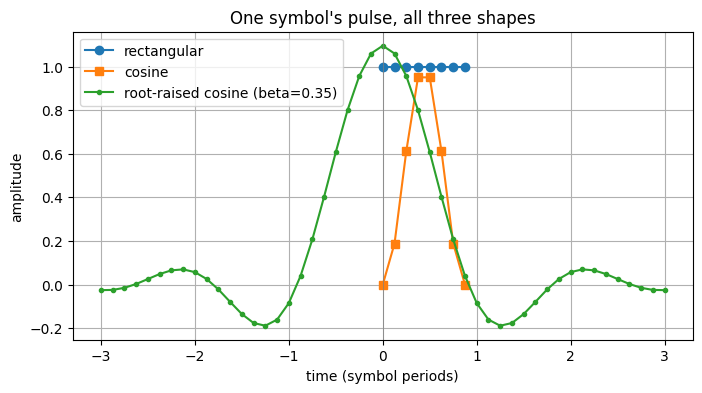

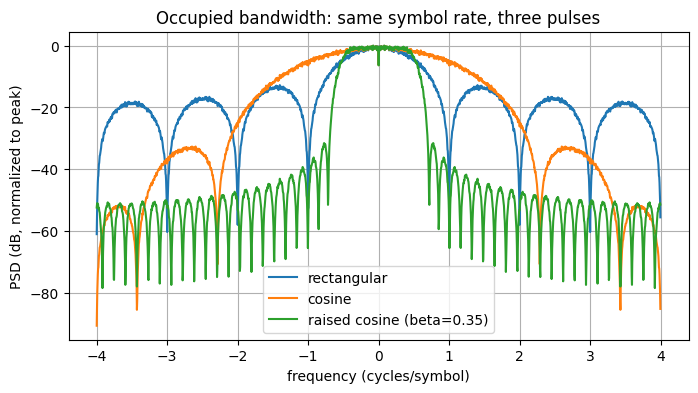

In [24]:
rect_pulse_arr = rect_pulse(sps)

# --- Time domain ---
plt.figure(figsize=(8, 4))
t_short = np.arange(sps) / sps
t_rc = (np.arange(len(rc_pulse_arr)) - len(rc_pulse_arr) // 2) / sps
plt.plot(t_short, rect_pulse_arr, 'o-', label='rectangular')
plt.plot(t_short, cos_pulse_arr, 's-', label='cosine')
plt.plot(t_rc, rc_pulse_arr, '.-', label=f'root-raised cosine (beta={rc_beta})')
plt.axvline(0, color='gray', linewidth=0.5)
plt.xlabel('time (symbol periods)')
plt.ylabel('amplitude')
plt.title("One symbol's pulse, all three shapes")
plt.legend()
plt.grid(True)
plt.show()

# --- Frequency domain: PSD of a noise-free transmitted BPSK waveform, each pulse ---
demo_bits = np.random.default_rng(2026).integers(0, 2, 20_000, dtype=np.int8)
demo_symbols, _ = bits_to_symbols(demo_bits, 'BPSK')

plt.figure(figsize=(8, 4))
for pulse, label in [(rect_pulse_arr, 'rectangular'),
                      (cos_pulse_arr, 'cosine'),
                      (rc_pulse_arr, f'raised cosine (beta={rc_beta})')]:
    waveform = pulse_shape(demo_symbols, pulse, sps)
    f, psd = welch(waveform, fs=sps, nperseg=2048, return_onesided=False)
    f, psd = np.fft.fftshift(f), np.fft.fftshift(psd)
    plt.plot(f, 10 * np.log10(psd / psd.max()), label=label)
plt.xlabel('frequency (cycles/symbol)')
plt.ylabel('PSD (dB, normalized to peak)')
plt.title('Occupied bandwidth: same symbol rate, three pulses')
plt.legend()
plt.grid(True)
plt.show()

## Task 9: Confirm the Zero-ISI Property

The RRC pulse alone does not have zero crossings at every symbol interval. The **combined
transmit pulse and matched filter** does: convolving the RRC pulse with its time-reversed
conjugate gives a raised-cosine-like response with zero crossings at nonzero symbol offsets.
The check below samples that combined response at symbol intervals.


In [25]:
# Combined response of the transmit RRC pulse and receive matched filter.
combined = np.convolve(rc_pulse_arr, np.conj(rc_pulse_arr[::-1]))
combined = combined / np.max(np.abs(combined))
center = len(combined) // 2
offsets = np.arange(-(rc_span // 2), rc_span // 2 + 1)
sample_indices = center + offsets * sps

print("Combined RRC + matched-filter response, sampled at symbol periods:")
for k, idx in zip(offsets, sample_indices):
    print(f"  {k:+d} symbol periods from center: {combined[idx]: .4f}")


Combined RRC + matched-filter response, sampled at symbol periods:
  -3 symbol periods from center:  0.0010
  -2 symbol periods from center:  0.0001
  -1 symbol periods from center:  0.0007
  +0 symbol periods from center:  1.0000
  +1 symbol periods from center:  0.0007
  +2 symbol periods from center:  0.0001
  +3 symbol periods from center:  0.0010


## Task 10: The Root-Raised-Cosine Pulse on the Air

Given in full -- every function from Part 1 (`build_tx_frame`, `capture`, `find_frame_start`,
`correct_frame`, `matched_filter_downsample`) already handles an arbitrary-length pulse, so
switching to the root-raised-cosine pulse is just a matter of passing `rc_pulse_arr` in instead.
This builds one frame, transmits, captures, corrects, and plots the received constellation --
confirm your BPSK symbols still land in two tight clusters at $\pm 1$, same as with the
cosine pulse in Task 5, despite the much longer pulse now in play.

Barker sync correlation=0.681


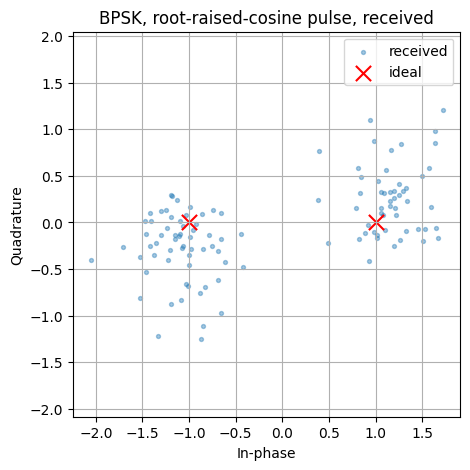

In [26]:
rc_frame, rc_used_bits = build_tx_frame(tx_bits, rc_pulse_arr, sps, preamble_len, preamble_scale)
rc_frame_len = frame_len_for(len(rc_used_bits), len(rc_pulse_arr), preamble_len, sps)
rc_rx_samples = capture(rc_frame, buffer_size_for(rc_frame_len))

rc_start = find_frame_start(rc_rx_samples, preamble_len, rc_frame_len)
rc_frame_slice = rc_rx_samples[rc_start:rc_start + rc_frame_len]
rc_corrected, *_ = correct_frame(rc_frame_slice, preamble_len, 1 + 0j, preamble_scale, fs)
rc_rx_syms = matched_filter_downsample(rc_corrected[preamble_len:], rc_pulse_arr, sps)
rc_rx_syms, rc_costas_phase = costas_loop_bpsk(rc_rx_syms[:len(tx_bits)], loop_bandwidth=0.02)

plt.figure(figsize=(5, 5))
plt.scatter(rc_rx_syms.real, rc_rx_syms.imag, s=8, alpha=0.4, label='received')
ideal = np.array(list(CONSTELLATIONS['BPSK'].values()))
plt.scatter(ideal.real, ideal.imag, s=120, marker='x', c='red', label='ideal')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('In-phase'); plt.ylabel('Quadrature')
plt.title('BPSK, root-raised-cosine pulse, received')
plt.show()

## Task 11: Single-Frame BER With the Root-Raised-Cosine Pulse, and the Full Comparison

Same `run_trial` call as Task 6, just with the root-raised-cosine pulse this time. The cell below
also reruns the rectangular pulse once for reference and prints all three BERs side by side --
given in full, since it's pure bookkeeping at this point.

In [27]:
# Software-only test: Barker sync and CFO/channel correction with a known delay.
# This does not transmit over SDR hardware.
_test_preamble = make_barker_preamble(sps, preamble_scale).astype(complex)
_test_payload_bits = np.array([0, 1, 1, 0, 1, 0, 0, 1], dtype=int)
_test_payload_syms, _ = bits_to_symbols(_test_payload_bits, "BPSK")
_test_payload = pulse_shape(_test_payload_syms, cosine_pulse(sps), sps)
_test_frame = np.concatenate([_test_preamble, _test_payload]).astype(complex)
_test_delay = 37
_test_cfo = 1800.0
_test_phase = 0.63
_test_gain = 0.7
_test_n = np.arange(len(_test_frame))
_test_rx_frame = _test_gain * _test_frame * np.exp(
    1j * (2*np.pi*_test_cfo*_test_n/fs + _test_phase)
)
_test_capture = np.concatenate([
    np.zeros(_test_delay, dtype=complex),
    _test_rx_frame,
    np.zeros(len(_test_frame), dtype=complex)
])
_test_frame_len = len(_test_frame)
_test_start = find_frame_start(_test_capture, preamble_len, _test_frame_len)
_test_slice = _test_capture[_test_start:_test_start + _test_frame_len]
_test_corrected, _test_fhat, _test_phihat, _test_ghat = correct_frame(
    _test_slice, preamble_len, 1 + 0j, preamble_scale, fs
)
print(f"Expected start={_test_delay}, detected={_test_start}")
print(f"Expected CFO={_test_cfo:.1f} Hz, estimated={_test_fhat:.1f} Hz")
print(f"Expected gain={_test_gain:.2f}, estimated={_test_ghat:.2f}")
assert _test_start == _test_delay, "Barker frame synchronization test failed"
assert abs(_test_fhat - _test_cfo) < 100, "Barker CFO estimate test failed"
assert abs(_test_ghat - _test_gain) < 0.05, "Barker gain estimate test failed"
print("Barker sync/CFO/channel-estimation software test passed.")


Barker sync correlation=0.847
Expected start=37, detected=37
Expected CFO=1800.0 Hz, estimated=1800.0 Hz
Expected gain=0.70, estimated=0.70
Barker sync/CFO/channel-estimation software test passed.


In [28]:
# Run each pulse using the selected SDR coding mode.
# For a coding comparison, change SDR_CODE in the message/encoder cell and rerun
# from that cell onward for each mode: uncoded, repetition, hamming74.
tx_gain_db = -40

ber_rect, total_rect, rx_syms_rect = run_trial(rect_pulse_arr, tx_gain_db, tx_bits)
ber_cos, total_cos, rx_syms_cos = run_trial(cos_pulse_arr, tx_gain_db, tx_bits)
ber_rc, total_rc, rx_syms_rc = run_trial(rc_pulse_arr, tx_gain_db, tx_bits)

print(f"\nSelected SDR coding mode: {SDR_CODE}")
print(f"{'pulse':<20}{'coded BER':>14}{'coded bits':>14}")
print(f"{'rectangular':<20}{ber_rect:>14.6f}{total_rect:>14d}")
print(f"{'cosine':<20}{ber_cos:>14.6f}{total_cos:>14d}")
print(f"{'root-raised cosine':<20}{ber_rc:>14.6f}{total_rc:>14d}")

# Decode recovered coded bits, then report information-bit BER and recovered text.
for pulse_name, symbols in [("rectangular", rx_syms_rect),
                            ("cosine", rx_syms_cos),
                            ("root-raised cosine", rx_syms_rc)]:
    rx_coded_bits = symbols_to_bits(symbols, "BPSK")
    rx_info_bits = decode_sdr_payload(
        rx_coded_bits, SDR_CODE, len(tx_info_bits), hamming_pad_bits
    )
    info_errors = int(np.count_nonzero(tx_info_bits != rx_info_bits))
    info_ber = info_errors / len(tx_info_bits) if len(tx_info_bits) else float("nan")
    print(f"\n{pulse_name}:")
    print(f"  Information-bit errors: {info_errors}/{len(tx_info_bits)}")
    print(f"  Information BER: {info_ber:.6f}")
    print(f"  Received message: {bits_to_message(rx_info_bits)}")


Barker sync correlation=0.758
Sync start=367, CFO=1876.9 Hz, phase=2.153 rad, gain=1.018, Costas final phase=-2.994 rad, RX symbols=112, errors=0/112
Barker sync correlation=0.762
Sync start=150, CFO=2001.0 Hz, phase=-0.967 rad, gain=1.13, Costas final phase=2.097 rad, RX symbols=112, errors=4/112
Barker sync correlation=0.734
Sync start=882, CFO=2170.9 Hz, phase=2.093 rad, gain=1.078, Costas final phase=1.114 rad, RX symbols=112, errors=0/112

Selected SDR coding mode: hamming74
pulse                    coded BER    coded bits
rectangular               0.000000           112
cosine                    0.035714           112
root-raised cosine        0.000000           112

rectangular:
  Information-bit errors: 0/64
  Information BER: 0.000000
  Received message: HELLO AI

cosine:
  Information-bit errors: 0/64
  Information BER: 0.000000
  Received message: HELLO AI

root-raised cosine:
  Information-bit errors: 0/64
  Information BER: 0.000000
  Received message: HELLO AI


## Background

**Why sharp edges cost bandwidth.** A signal's spectrum is its Fourier transform, and an
instantaneous jump in amplitude -- exactly what the rectangular pulse does at every symbol
boundary -- requires energy at arbitrarily high frequencies to reproduce. Formally, the
Fourier transform of a rectangular pulse of duration $T$ is a sinc function, whose sidelobes
decay only as $1/f$: slowly enough that a real system has to either accept significant
out-of-band leakage or filter it away after the fact. The cosine pulse's edges are smoother --
its value and slope both go to zero at the boundary -- and that extra smoothness is exactly
why its spectrum decays faster than the rectangular pulse's. It's still confined to one symbol
period, though, so there's a limit to how smooth its edges can be, and its spectrum still has
more energy far from the carrier than a real bandwidth-constrained system would like.

**Nyquist's zero-ISI criterion.** The raised-cosine pulse takes a completely different
approach: instead of confining the pulse to one symbol period, let it spread across several,
but design it so that at every *other* symbol's sampling instant, its value is exactly zero.
Task 9 confirmed exactly this. That's Nyquist's criterion for ISI-free transmission -- a pulse
doesn't need to be zero everywhere outside its own symbol period, it only needs to cross zero
at every *other* symbol's sampling instant. Sample at the wrong time, even by a fraction of a
symbol period, and that zero-crossing property is lost -- neighboring symbols' tails no longer
cancel, and you get real interference. This is exactly why frame sync (Task 5's job, all lab)
matters as much as it does: a raised-cosine pulse is far less forgiving of timing error than a
rectangular one.

**The role of $\beta$.** The roll-off factor trades bandwidth against time-domain decay.
$\beta \to 0$ gives the narrowest possible bandwidth (approaching the ideal $\text{sinc}$
pulse) but the raised-cosine pulse's tails decay very slowly in that limit, making it
extremely sensitive to timing error. $\beta \to 1$ gives the fastest-decaying tails -- more
forgiving of timing error -- at the cost of using roughly twice the bandwidth of the
zero-roll-off case. Real systems pick something in between (0.35 in this lab, a value used in
several real standards) as a practical compromise.

**One thing to flag for later, not required here:** using the raised-cosine pulse itself as
the matched filter (as this lab does) is one valid choice, but it's not the only one. Splitting
the raised-cosine response evenly between transmitter and receiver -- each side applying a
*square-root* raised-cosine pulse -- is what most real systems actually do, and it has real
advantages once channel effects beyond thermal noise are in the picture. Worth keeping in mind
if you go further in this area, but nothing in this lab depends on it.

## Reflection Questions

1. Why does the rectangular pulse's instant on/off transition lead to a spectrum that decays
   so slowly with frequency?
2. The cosine pulse tapers smoothly to zero at both edges. Does that completely eliminate
   spectral leakage outside the symbol's nominal bandwidth, or just reduce it? Why?
3. The raised-cosine pulse deliberately spreads one symbol's energy across several neighboring
   symbol periods -- yet Task 9 showed no interference at the correct sampling instant. In
   your own words, why doesn't the overlap in time cause a problem?
4. Suppose the receiver sampled the raised-cosine matched-filter output slightly off from the
   correct instant -- not exactly at the peak. Would every value of $\beta$ be equally
   forgiving of that timing error, or would some be more sensitive than others?
5. All three pulses in this lab were normalized so that BPSK's matched-filter output lands on
   the same $\pm 1$ regardless of which pulse was used, and Task 11's BER numbers came out
   close to each other as a result. Given that, what's actually being bought by moving to a
   more complicated pulse than the rectangular one?

# Consolidated comparison: uncoded vs Repetition (3,1) vs Hamming (7,4)

This section runs **all three coding modes in one go** and plots them side by side. The software simulation runs without SDR hardware. The hardware comparison is included below and is disabled by default so that a notebook run does not unexpectedly transmit over radio.

- **Uncoded:** baseline BPSK, no error correction.
- **Repetition (3,1):** each information bit is sent three times and decoded by majority vote.
- **Hamming (7,4):** four information bits are mapped to seven coded bits; the syndrome decoder corrects one bit error per codeword.

For a fair software BER comparison, the simulated BPSK symbol amplitude is scaled by the square root of the code rate, so the average energy per information bit is normalized across schemes.

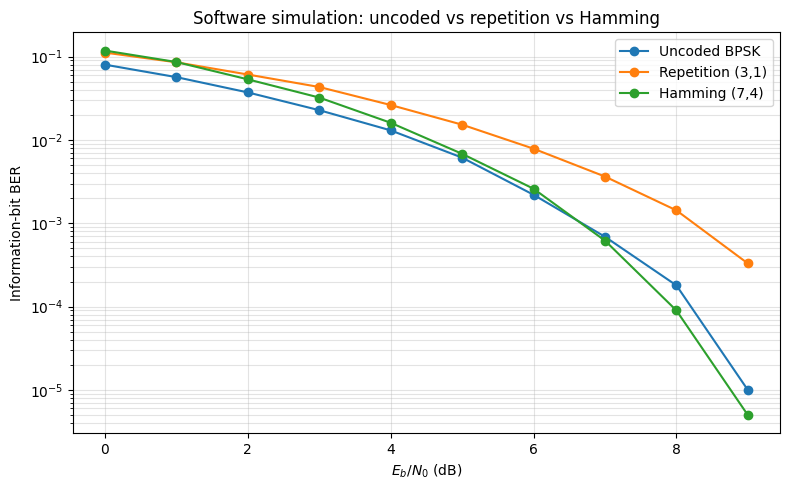

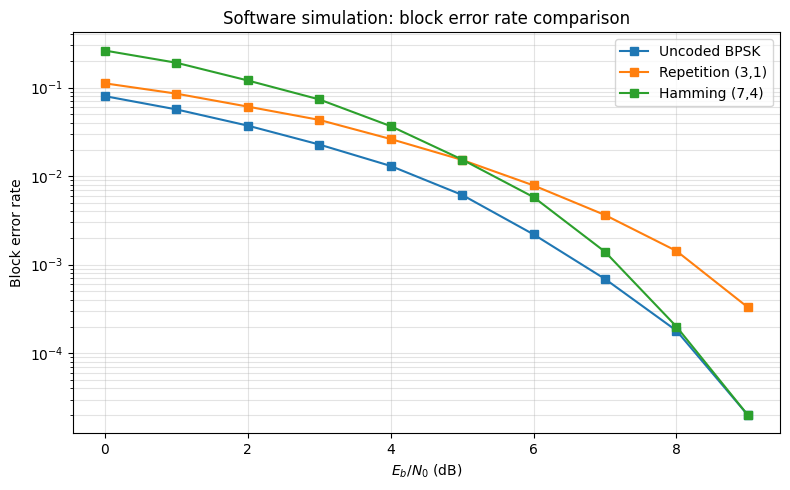

Software simulation complete. BER arrays:
Uncoded BPSK        : 0.0801, 0.0568, 0.0372, 0.0228, 0.013, 0.00614, 0.0022, 0.00069, 0.00018, 1e-05
Repetition (3,1)    : 0.112, 0.0855, 0.061, 0.0432, 0.0263, 0.0153, 0.00786, 0.00364, 0.00143, 0.00033
Hamming (7,4)       : 0.118, 0.0861, 0.0534, 0.0323, 0.0161, 0.00682, 0.0026, 0.00062, 9e-05, 0


In [29]:
# Software-only Monte Carlo comparison. No PlutoSDR is required.
import numpy as np
import matplotlib.pyplot as plt

LAB9_EBN0_DB = np.arange(0, 10, 1)
LAB9_N_INFO_BITS = 100_000  # increase for smoother low-BER estimates
LAB9_RNG = np.random.default_rng(20261016)

# Standalone coding helpers for the comparison section.
def lab9_rep_encode(bits):
    return np.repeat(np.asarray(bits, dtype=np.int8), 3)

def lab9_rep_decode(bits):
    b = np.asarray(bits, dtype=np.int8).reshape(-1, 3)
    return (b.sum(axis=1) >= 2).astype(np.int8)

def lab9_h74_encode(bits):
    bits = np.asarray(bits, dtype=np.int8).ravel()
    pad = (-len(bits)) % 4
    if pad:
        bits = np.concatenate([bits, np.zeros(pad, dtype=np.int8)])
    m = bits.reshape(-1, 4)
    d1, d2, d3, d4 = m.T
    p1 = d1 ^ d2 ^ d4
    p2 = d1 ^ d3 ^ d4
    p4 = d2 ^ d3 ^ d4
    return np.column_stack([p1, p2, d1, p4, d2, d3, d4]).reshape(-1), pad

def lab9_h74_decode(bits):
    words = np.asarray(bits, dtype=np.int8).ravel().reshape(-1, 7).copy()
    s1 = words[:, 0] ^ words[:, 2] ^ words[:, 4] ^ words[:, 6]
    s2 = words[:, 1] ^ words[:, 2] ^ words[:, 5] ^ words[:, 6]
    s4 = words[:, 3] ^ words[:, 4] ^ words[:, 5] ^ words[:, 6]
    syndrome = s1 + 2*s2 + 4*s4
    for row, syn in enumerate(syndrome):
        if syn:
            words[row, int(syn)-1] ^= 1
    return words[:, [2, 4, 5, 6]].reshape(-1)

# Make one information sequence shared by every scheme and Eb/N0 point.
lab9_info = LAB9_RNG.integers(0, 2, LAB9_N_INFO_BITS, dtype=np.int8)
lab9_encoded = {
    'Uncoded BPSK': (lab9_info.copy(), 1.0, lambda b: b),
    'Repetition (3,1)': (lab9_rep_encode(lab9_info), 1/3, lab9_rep_decode),
}
lab9_ham_bits, lab9_ham_pad = lab9_h74_encode(lab9_info)
lab9_encoded['Hamming (7,4)'] = (lab9_ham_bits, 4/7,
                                  lambda b: lab9_h74_decode(b)[:len(lab9_info)])

lab9_sim_ber = {name: [] for name in lab9_encoded}
lab9_sim_bler = {name: [] for name in lab9_encoded}
for ebn0_db in LAB9_EBN0_DB:
    ebn0 = 10**(ebn0_db/10)
    sigma = np.sqrt(1/(2*ebn0))  # normalized Eb=1 per information bit
    for name, (coded, rate, decoder) in lab9_encoded.items():
        # Unit energy per information bit: coded-symbol amplitude sqrt(code rate).
        tx_symbols = (2*coded.astype(float)-1) * np.sqrt(rate)
        rx_symbols = tx_symbols + LAB9_RNG.normal(0, sigma, size=len(tx_symbols))
        rx_coded = (rx_symbols >= 0).astype(np.int8)
        decoded = decoder(rx_coded)[:len(lab9_info)]
        nerr = int(np.count_nonzero(decoded != lab9_info))
        lab9_sim_ber[name].append(nerr/len(lab9_info))
        # BLER is measured in natural decoder blocks: 1 bit, 1 bit, or 4 bits.
        if name == 'Hamming (7,4)':
            tx_blocks = lab9_info[:(len(lab9_info)//4)*4].reshape(-1, 4)
            rx_blocks = decoded[:len(tx_blocks)*4].reshape(-1, 4)
        else:
            tx_blocks = lab9_info.reshape(-1, 1)
            rx_blocks = decoded.reshape(-1, 1)
        lab9_sim_bler[name].append(float(np.mean(np.any(tx_blocks != rx_blocks, axis=1))))

# BER plot: all coding modes on the same axes.
plt.figure(figsize=(8, 5))
for name, values in lab9_sim_ber.items():
    safe = np.maximum(values, 0.5/LAB9_N_INFO_BITS)
    plt.semilogy(LAB9_EBN0_DB, safe, marker='o', label=name)
plt.xlabel(r'$E_b/N_0$ (dB)')
plt.ylabel('Information-bit BER')
plt.title('Software simulation: uncoded vs repetition vs Hamming')
plt.grid(True, which='both', alpha=0.35)
plt.legend()
plt.tight_layout()
plt.show()

# BLER plot: all coding modes on the same axes.
plt.figure(figsize=(8, 5))
for name, values in lab9_sim_bler.items():
    safe = np.maximum(values, 0.5/max(1, LAB9_N_INFO_BITS//4))
    plt.semilogy(LAB9_EBN0_DB, safe, marker='s', label=name)
plt.xlabel(r'$E_b/N_0$ (dB)')
plt.ylabel('Block error rate')
plt.title('Software simulation: block error rate comparison')
plt.grid(True, which='both', alpha=0.35)
plt.legend()
plt.tight_layout()
plt.show()

print('Software simulation complete. BER arrays:')
for name, values in lab9_sim_ber.items():
    print(f'{name:20s}: ' + ', '.join(f'{v:.3g}' for v in values))

## SDR comparison: all three coding modes in one run

This section uses the notebook's existing Lab 8 SDR chain (Barker-13 synchronization, coarse carrier correction, matched filtering, and Costas loop). It automatically transmits and receives **uncoded, repetition, and Hamming** payloads in sequence using the same pulse shape and RF settings, then plots the results side by side.

**Hardware note:** This comparison needs both PlutoSDRs connected and configured. Keep `RUN_SDR_COMPARISON = False` until you are ready to transmit. One trial is performed per coding mode (per pulse shape), so results may vary with the RF channel. For a controlled comparison, keep TX gain, RX gain, sample rate, carrier frequency, and physical setup unchanged.


--- SDR mode: uncoded | info bits=64 | coded bits=64 ---
Barker sync correlation=0.724
Sync start=680, CFO=2106.7 Hz, phase=2.483 rad, gain=1.073, Costas final phase=0.763 rad, RX symbols=64, errors=0/64
Coded-bit BER: 0.000000
Information-bit errors: 0/64; BER=0.000000
Received message: HELLO AI

--- SDR mode: repetition | info bits=64 | coded bits=192 ---
Barker sync correlation=0.677
Sync start=540, CFO=2408.0 Hz, phase=0.792 rad, gain=1.065, Costas final phase=-1.949 rad, RX symbols=192, errors=0/192
Coded-bit BER: 0.000000
Information-bit errors: 0/64; BER=0.000000
Received message: HELLO AI

--- SDR mode: hamming74 | info bits=64 | coded bits=112 ---
Barker sync correlation=0.715
Sync start=1965, CFO=2178.5 Hz, phase=2.636 rad, gain=1.115, Costas final phase=1.100 rad, RX symbols=112, errors=0/112
Coded-bit BER: 0.000000
Information-bit errors: 0/64; BER=0.000000
Received message: HELLO AI


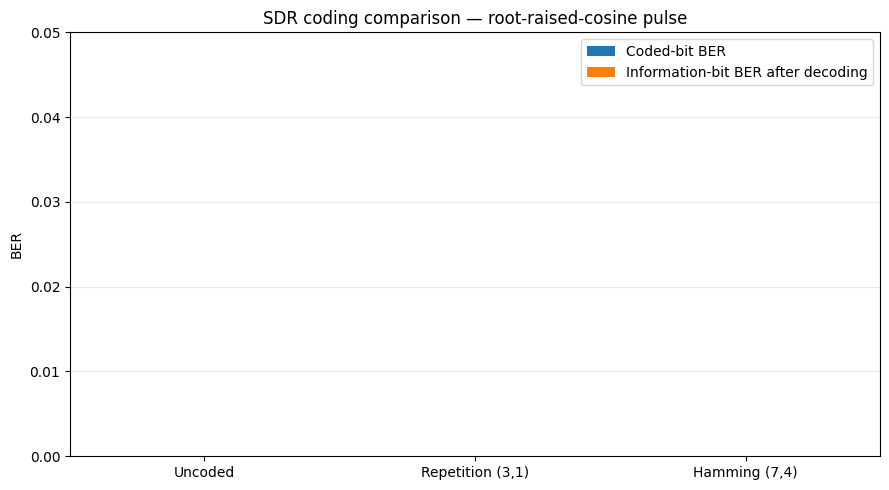

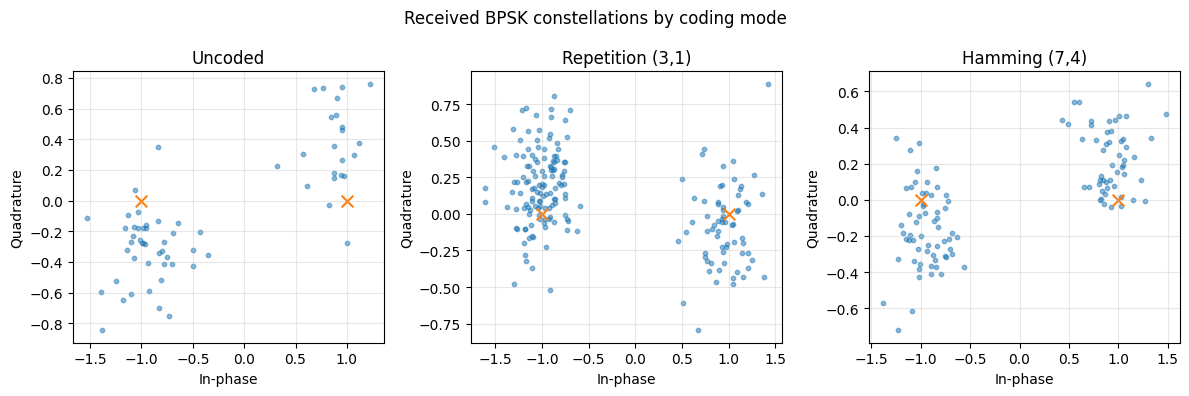


Summary table
Mode               Coded BER    Info BER   Info errorsRecovered message
uncoded             0.000000    0.000000        0/64     HELLO AI
repetition          0.000000    0.000000        0/64     HELLO AI
hamming74           0.000000    0.000000        0/64     HELLO AI


In [30]:
# Set True only when both PlutoSDRs are connected and you are ready to transmit.
RUN_SDR_COMPARISON = True
SDR_COMPARE_MESSAGE = MESSAGE  # uses the same readable message for every coding mode
SDR_COMPARE_PULSE_NAME = 'root-raised-cosine'  # use the same pulse for a fair code comparison
SDR_COMPARE_TX_GAIN_DB = -40

if not RUN_SDR_COMPARISON:
    print('SDR comparison is disabled. Set RUN_SDR_COMPARISON = True to run all three modes.')
else:
    # Use existing Lab 8 pulse definitions and run_trial() function.
    pulse_lookup = {
        'rectangular': rect_pulse_arr,
        'cosine': cos_pulse_arr,
        'root-raised-cosine': rc_pulse_arr,
    }
    compare_pulse = pulse_lookup[SDR_COMPARE_PULSE_NAME]
    compare_info_bits = message_to_bits(SDR_COMPARE_MESSAGE)
    compare_results = {}

    # All modes run automatically in this one cell; no manual mode switching.
    for mode in ('uncoded', 'repetition', 'hamming74'):
        coded_bits, pad_bits = encode_sdr_payload(compare_info_bits, mode)
        print(f'\n--- SDR mode: {mode} | info bits={len(compare_info_bits)} | coded bits={len(coded_bits)} ---')
        coded_ber, n_coded, rx_symbols = run_trial(
            compare_pulse, SDR_COMPARE_TX_GAIN_DB, coded_bits
        )
        rx_coded_bits = symbols_to_bits(rx_symbols, 'BPSK')
        rx_info_bits = decode_sdr_payload(
            rx_coded_bits, mode, len(compare_info_bits), pad_bits
        )
        info_errors = int(np.count_nonzero(compare_info_bits != rx_info_bits))
        info_ber = info_errors / len(compare_info_bits)
        recovered = bits_to_message(rx_info_bits)
        compare_results[mode] = {
            'coded_ber': coded_ber,
            'info_ber': info_ber,
            'coded_bits': n_coded,
            'info_errors': info_errors,
            'rx_symbols': rx_symbols.copy(),
            'message': recovered,
        }
        print(f'Coded-bit BER: {coded_ber:.6f}')
        print(f'Information-bit errors: {info_errors}/{len(compare_info_bits)}; BER={info_ber:.6f}')
        print('Received message:', recovered)

    # Side-by-side BER comparison: coded BER and post-decoding information BER.
    mode_labels = ['uncoded', 'repetition', 'hamming74']
    coded_vals = [compare_results[m]['coded_ber'] for m in mode_labels]
    info_vals = [compare_results[m]['info_ber'] for m in mode_labels]
    x = np.arange(len(mode_labels))
    width = 0.36
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(x - width/2, coded_vals, width, label='Coded-bit BER')
    ax.bar(x + width/2, info_vals, width, label='Information-bit BER after decoding')
    ax.set_xticks(x, ['Uncoded', 'Repetition (3,1)', 'Hamming (7,4)'])
    ax.set_ylabel('BER')
    ax.set_ylim(0, max(0.05, min(1.0, max(coded_vals + info_vals, default=0) * 1.2)))
    ax.set_title(f'SDR coding comparison — {SDR_COMPARE_PULSE_NAME} pulse')
    ax.grid(True, axis='y', alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

    # Side-by-side constellation plots for all coding modes.
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, mode, title in zip(axes, mode_labels, ['Uncoded', 'Repetition (3,1)', 'Hamming (7,4)']):
        z = compare_results[mode]['rx_symbols']
        ax.scatter(z.real, z.imag, s=10, alpha=0.5)
        ax.scatter([-1, 1], [0, 0], marker='x', s=70)
        ax.set_title(title)
        ax.set_xlabel('In-phase')
        ax.set_ylabel('Quadrature')
        ax.grid(True, alpha=0.3)
    fig.suptitle('Received BPSK constellations by coding mode')
    plt.tight_layout()
    plt.show()

    print('\nSummary table')
    print(f"{'Mode':<16}{'Coded BER':>12}{'Info BER':>12}{'Info errors':>14}{'Recovered message'}")
    for mode in mode_labels:
        r = compare_results[mode]
        print(f"{mode:<16}{r['coded_ber']:>12.6f}{r['info_ber']:>12.6f}{r['info_errors']:>9}/{len(compare_info_bits):<5}  {r['message']}")

### How to interpret the comparison

- Compare **information-bit BER after decoding** to evaluate the benefit of error-control coding.
- Coded-bit BER is useful for examining the physical BPSK link, but it is not directly equivalent across schemes because each mode transmits a different number of coded bits.
- Repetition (3,1) uses three transmitted symbols per information bit; Hamming (7,4) uses 1.75. Their airtime and error-correction behavior therefore differ.
- A single physical SDR trial is not enough for a statistically strong result. Repeat the three-mode comparison several times under the same RF conditions and average the BER values before drawing conclusions.
- The software simulation and SDR results should be presented separately: software AWGN results are reproducible, while physical SDR results depend on the hardware and channel.